# 08 — Evaluation on the held-out cohorts

This notebook first writes the pre-registered success criteria to
`docs/decisions.md` (#5), then — and only then — scores every model on the
requests that entered the queue in 2017–2019 (Track A) and in 2017 (Track
B): discrimination, Brier score, calibration and ranking value with
bootstrap intervals, the criteria's PASS/FAIL verdicts, and the secondary
analyses (7-year check, leave-one-ISO-out, leakage ablation, robustness
reruns).

**Inputs → Outputs**

| | Path | Notes |
|---|---|---|
| in | `data/processed/predictions_trackA.parquet` | notebooks 05–06 — baseline, Cox, discrete-time logit and LightGBM P(operation by 3/5/7 yr), with the observed outcome |
| in | `data/processed/predictions_trackB.parquet` | notebook 07 — base rate, logit and LightGBM P(built), raw and calibrated |
| in | `data/interim/trackA.parquet`, `data/interim/queue_clean.parquet`, `data/interim/queue_events.parquet` | notebooks 02/04 — for refits, follow-up windows and Track B's unresolved share |
| in | `results/dt_tuning.json` | notebook 06 — model settings reused by every refit |
| out | `docs/decisions.md` (#5), `results/success_criteria_registered.json` | the criteria, written by the first cell before any data are read |
| out | `results/test_outcome_status.csv`, `results/metrics.csv`, `results/metrics_by_region.csv` | outcome status by horizon; every model × horizon × metric with a 95% interval |
| out | `results/calibration.csv`, `results/calibration_by_region.csv`, `results/gains.csv` | calibration by predicted decile and by region; gains curves |
| out | `results/trackB_test_by_region.csv`, `results/success_criteria.csv` | Track B per region; PASS/FAIL per criterion |
| out | `results/seven_year_check.csv`, `results/cohort_check.csv`, `results/loio.csv`, `results/ablation.csv`, `results/robustness.csv`, `results/evaluate_checks.csv` | secondary analyses and checks |
| out | `figures/F4_*.png|svg`, `figures/F5_*.png|svg`, `figures/08_evaluate/*.png|svg`, `report/figure_notes.md` | report figures F4, F5 and the exploratory figures |

## 0. Pre-registered success criteria

The next cell runs before any data are read. It writes the criteria Alan
approved on 2026-10-04 (journal, question 9: "beat" by interval, model lift
≥ 1.5, the primary models as drafted) into `docs/decisions.md` as decision
#5, and a machine-readable copy to `results/success_criteria_registered.json`
that section 6 reads to decide PASS or FAIL. The decision text was committed
on its own before the first scoring run, so the git history shows the
criteria existed before any test metric did.

In [1]:
# Pre-registration: this cell reads no data
import json
import re
from pathlib import Path

REPO = Path.cwd().resolve().parent

DECISION_5 = """5. **Pre-registered success criteria** (Alan, 2026-10-04; written by the
   first cell of notebook 08 before any test data were read, and committed
   on its own before the first scoring run). Test sets: Track A requests
   entering 2017–2019 with outcomes through 2024-12-31; Track B resolved
   requests entering in 2017.
   *Primary models, named before scoring:* Track A — discrete-time LightGBM
   (`dt_lgbm`, lowest 2016 log loss in notebook 06); Track B — calibrated
   LightGBM (`lgbm_cal`). The discrete-time logit, Cox and the uncalibrated
   Track B models are reported beside them and decide nothing.
   *Benchmarks:* region × technology Aalen–Johansen cells (Track A, notebook
   05); region × technology base rates (Track B, notebook 07).
   - **C1** Uno's concordance index of P(operation by t), withdrawal as a
     competing event, above the baseline's at t = 3, 5 and 7 years.
   - **C2** IPCW Brier score below the baseline's at 3, 5 and 7 years.
   - **C3** Calibration slope between 0.9 and 1.1 at 3, 5 and 7 years.
   - **C4** Top-decile lift at 5 years ≥ 1.5: the share reaching operation
     within 5 years among the 10% of test requests with the highest
     predictions, divided by the share in the whole test cohort.
   - **C5** Track B, 2017 cohort: AUC above and Brier score below the base
     rate's.
   *"Beat"* (C1, C2, C5) means that the 95% percentile interval of the
   paired difference model − benchmark, from 200 bootstrap resamples of test
   requests (seeds 800 for Track A and 801 for Track B, recorded in
   `results/success_criteria_registered.json`), lies entirely on the better
   side of zero.
   *Thresholds* (C3, C4) are judged on the point estimate; the interval is
   reported. Each criterion × horizon is one PASS/FAIL line of
   `results/success_criteria.csv` (12 lines); point estimates are reported
   either way, failures are reported, not removed, and no criterion is
   changed after scoring.
   *Outcome and censoring:* for "operation by t" a request that withdrew
   before t is a known non-event; only requests still waiting on 2024-12-31
   before reaching t are censored, with inverse-probability-of-censoring
   weights from a Kaplan–Meier estimate of the censoring distribution. All
   censoring is administrative (2024-12-31), so that distribution is the
   distribution of the test requests' follow-up windows (2024-12-31 minus the
   request date), which is known at entry; every test request has at least
   five years, so the weights differ from 1 only at 7 years. The 7-year
   horizon is fully observed only for 2017 entrants; this is stated with
   every 7-year number, and the 7-year metrics are also reported for 2017
   entrants alone. *Change from the draft (journal, question 9):* the draft
   took the censoring distribution from the training set, whose requests
   have at least eight years of follow-up, so every weight would be 1 and the
   7-year metrics would silently drop the 2018–2019 requests still waiting.
   Changed before any test data were read.
   *Reported, not criteria:* Harrell's concordance, time-dependent AUC,
   calibration intercept and deciles, precision in the top 10%, metrics by
   region, the 7-year check on 2017 entrants, leave-one-ISO-out, the leakage
   ablation and the robustness reruns.
   *Rejected:* "beat" on point estimates (a difference inside the noise
   would count as a win); lift ≥ 1.5 × the baseline's lift (Alan, question
   9b).
"""

REGISTERED = {
    "decided": "2026-10-04",
    "n_boot": 200,
    "level": 0.95,
    "seed_track_a": 800,
    "seed_track_b": 801,
    "criteria": [
        {"id": "C1", "track": "A", "model": "dt_lgbm", "benchmark": "baseline", "metric": "uno_c",
         "horizons": [3, 5, 7], "rule": "beat"},
        {"id": "C2", "track": "A", "model": "dt_lgbm", "benchmark": "baseline", "metric": "brier",
         "horizons": [3, 5, 7], "rule": "beat"},
        {"id": "C3", "track": "A", "model": "dt_lgbm", "metric": "slope", "horizons": [3, 5, 7],
         "rule": "between", "low": 0.9, "high": 1.1},
        {"id": "C4", "track": "A", "model": "dt_lgbm", "metric": "lift_10", "horizons": [5],
         "rule": "at least", "value": 1.5},
        {"id": "C5", "track": "B", "model": "lgbm_cal", "benchmark": "baseline", "metric": "auc",
         "horizons": [None], "rule": "beat"},
        {"id": "C5", "track": "B", "model": "lgbm_cal", "benchmark": "baseline", "metric": "brier",
         "horizons": [None], "rule": "beat"},
    ],
}

decisions_file = REPO / "docs" / "decisions.md"
text = decisions_file.read_text(encoding="utf-8")
entry = re.compile(r"^5\. \*\*Pre-registered success criteria\*\*.*?(?=^6\. \*\*)", re.M | re.S)
assert len(entry.findall(text)) == 1, "decision #5 not found exactly once"
updated = entry.sub(lambda _: DECISION_5, text)
if updated != text:
    decisions_file.write_text(updated, encoding="utf-8")
(REPO / "results" / "success_criteria_registered.json").write_text(json.dumps(REGISTERED, indent=2), encoding="utf-8")
n_lines = sum(len(c["horizons"]) for c in REGISTERED["criteria"])
print(f"decision #5 {'written' if updated != text else 'already in place'}; {n_lines} criterion lines registered")

decision #5 already in place; 12 criterion lines registered


## Setup

Metrics are in `src/evaluation.py`: `censoring_km` (censoring
distribution), `horizon_outcome` (operated by t, with its IPCW weight —
withdrawal is a known non-event), `concordance` (Harrell's and Uno's, with
withdrawal as a competing event), `auc`, `brier`,
`calibration_slope_intercept`, `top_fraction` (precision and lift with ties
shared), `score` / `score_horizon` (all of them for several models),
`bootstrap` (resampled requests, paired across models) and `summarise`
(estimates, intervals and differences from the baseline). Refits for the
secondary analyses use `discrete_time.fit_both` / `predict_both` with
notebook 06's settings.

In [2]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import config, discrete_time, evaluation, paths, plots, survival_tools, track_b

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

NOTEBOOK = "08_evaluate"
TRACK_A = config.TRACK_A_REGIONS


def save(fig, name, caption):
    """Save a figure of this notebook under figures/08_evaluate/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)


def pct(x, digits=1):
    """Format a share as a percentage string."""
    return f"{100 * x:.{digits}f}%"

import time
import warnings

from sklearn.metrics import roc_curve

warnings.filterwarnings("ignore", category=FutureWarning)
START = time.time()
HORIZONS = config.HORIZONS
N_BOOT, LEVEL = REGISTERED["n_boot"], REGISTERED["level"]
MODELS = ["baseline", "cox", "dt_logit", "dt_lgbm"]
MODEL_LABELS = {"baseline": "Baseline (region × technology)", "cox": "Cox", "dt_logit": "Discrete-time logit",
                "dt_lgbm": "Discrete-time LightGBM"}
MODEL_STYLE = {"baseline": dict(color="#999999", marker="s", linestyle="--"),
               "cox": dict(color="#555555", marker="D", linestyle=":"),
               "dt_logit": dict(color="#009E73", marker="o"),
               "dt_lgbm": dict(color="#CC79A7", marker="^")}
METRIC_LABELS = {"uno_c": "Uno's C", "harrell_c": "Harrell's C", "auc": "Time-dependent AUC",
                 "brier": "Brier score (IPCW)", "slope": "Calibration slope", "intercept": "Calibration intercept",
                 "precision_10": "Precision in top 10%", "lift_10": "Top-decile lift"}
OFFSETS = dict(zip(MODELS, np.linspace(-0.24, 0.24, len(MODELS))))


def value(table, model, metric, horizon=None, column="estimate"):
    """One number from a summarised metrics table."""
    part = table[(table["model"] == model) & (table["metric"] == metric)]
    if horizon is not None:
        part = part[part["horizon"] == horizon]
    assert len(part) == 1, (model, metric, horizon)
    return part[column].iloc[0]


def ci(table, model, metric, horizon=None, digits=3, prefix=""):
    """'estimate [low, high]' for one row of a summarised table (prefix 'diff' for the paired difference)."""
    cols = [f"{prefix}{c}" if prefix else c for c in (["diff", "diff_low", "diff_high"] if prefix else ["estimate", "low", "high"])]
    est, low, high = (value(table, model, metric, horizon, c) for c in cols)
    return f"{est:.{digits}f} [{low:.{digits}f}, {high:.{digits}f}]"


def errorbars(ax, x, part, **style):
    """Points with their bootstrap interval."""
    return ax.errorbar(x, part["estimate"], yerr=[part["estimate"] - part["low"], part["high"] - part["estimate"]],
                       capsize=3, **style)

## 1. The test cohort and what is known about it at each horizon

Track A's test set is every request that entered the CAISO, ERCOT or PJM
queue in 2017–2019 (notebook 04's split). For P(operation by t) each request
is in one of four states at year t: operated, withdrew (a known non-event),
still waiting (a known non-event at t), or censored before t — still waiting
on 2024-12-31 with less than t years of follow-up, so its status at t is
unknown. The predictions were written by notebooks 05 and 06 before this
notebook existed; here they are joined to the outcomes for the first time.

test requests: 2,268; by entry year {np.int64(2017): 549, np.int64(2018): 672, np.int64(2019): 1047}; by region {'PJM': 1465, 'ERCOT': 479, 'CAISO': 324}
follow-up windows: 5.01–7.99 years; censored requests whose duration equals their window: True


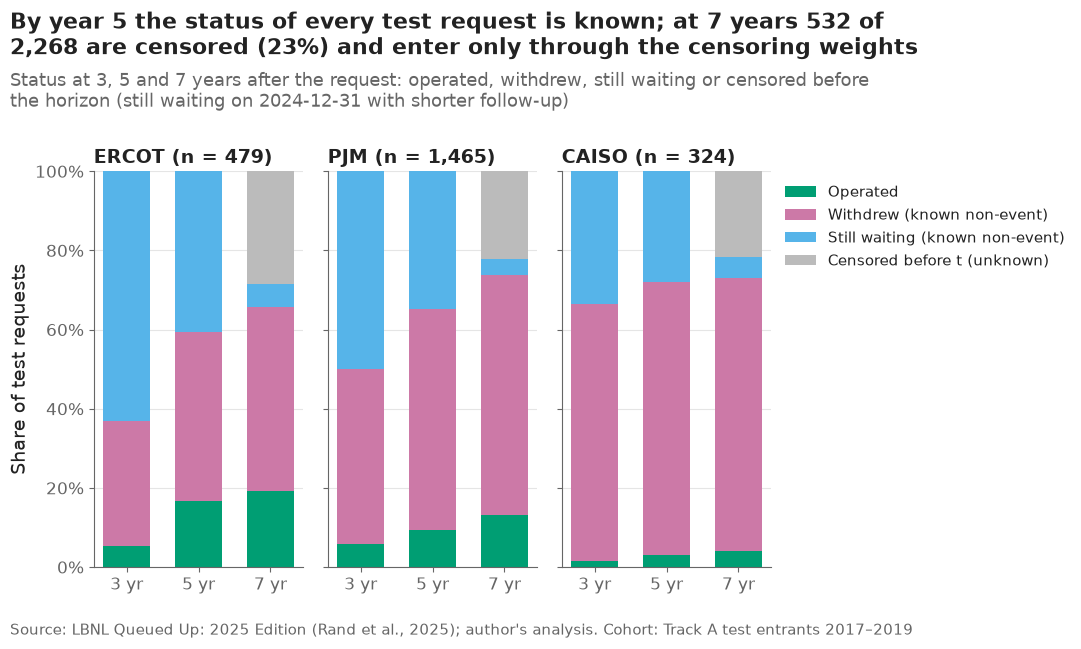

n  operated  withdrew  waiting  unknown
horizon region                                            
3       ERCOT    479        26       151      302        0
        PJM     1465        87       648      730        0
        CAISO    324         5       210      109        0
        all     2268       118      1009     1141        0
5       ERCOT    479        80       204      195        0
        PJM     1465       137       819      509        0
        CAISO    324        10       223       91        0
        all     2268       227      1246      795        0
7       ERCOT    479        92       223       28      136
        PJM     1465       192       891       56      326
        CAISO    324        13       224       17       70
        all     2268       297      1338      101      532

In [3]:
pred = pd.read_parquet(paths.DATA_PROCESSED / "predictions_trackA.parquet")
track_a = pd.read_parquet(paths.DATA_INTERIM / "trackA.parquet")
track_a["tech"] = track_a["type_clean"].map(plots.tech_group)
test = track_a[track_a["q_year"].between(*config.TEST_YEARS)].copy()
keys = test["project_key"].astype(str)
P = {h: pred[(pred["split"] == "test") & (pred["horizon"] == h)].set_index("project_key").loc[keys] for h in HORIZONS}
assert all(np.allclose(P[h]["duration_years"], test["duration_years"]) for h in HORIZONS)
durations = test["duration_years"].to_numpy()
events = test["event"].to_numpy()
regions = test["region"].astype(str).to_numpy()
preds = {h: {m: P[h][m].to_numpy() for m in MODELS} for h in HORIZONS}
follow_up = ((pd.Timestamp(config.CENSOR_DATE) - test["q_date"]).dt.days / config.DAYS_PER_YEAR).to_numpy()
print(f"test requests: {len(test):,}; by entry year {test['q_year'].value_counts().sort_index().to_dict()}; "
      f"by region {test['region'].value_counts().to_dict()}")
print(f"follow-up windows: {follow_up.min():.2f}–{follow_up.max():.2f} years; censored requests whose duration equals "
      f"their window: {np.allclose(durations[events == 0], follow_up[events == 0])}")

status_rows = []
for h in HORIZONS:
    states = {"operated": (events == 1) & (durations <= h), "withdrew": (events == 2) & (durations <= h),
              "waiting": durations > h, "unknown": (events == 0) & (durations <= h)}
    for region in TRACK_A + ["all"]:
        mask = np.ones(len(test), bool) if region == "all" else regions == region
        status_rows.append({"region": region, "horizon": h, "n": int(mask.sum()),
                            **{k: int((v & mask).sum()) for k, v in states.items()}})
status = pd.DataFrame(status_rows)
status.to_csv(paths.RESULTS / "test_outcome_status.csv", index=False)

STATE_COLORS = {"operated": config.OUTCOME_COLORS["operation"], "withdrew": config.OUTCOME_COLORS["withdrawal"],
                "waiting": "#56B4E9", "unknown": "#BBBBBB"}
fig, axes = plt.subplots(1, 3, sharey=True)
for ax, region in zip(axes, TRACK_A):
    part = status[status["region"] == region].set_index("horizon")
    bottom = np.zeros(len(part))
    for state, color in STATE_COLORS.items():
        share = part[state] / part["n"]
        ax.bar([f"{h} yr" for h in part.index], share, bottom=bottom, color=color, width=0.65,
               label={"operated": "Operated", "withdrew": "Withdrew (known non-event)",
                      "waiting": "Still waiting (known non-event)", "unknown": "Censored before t (unknown)"}[state])
        bottom += share.to_numpy()
    ax.set_title(f"{region} (n = {int(part['n'].iloc[0]):,})")
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[0].set_ylabel("Share of test requests")
axes[2].legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=11)
allr = status[status["region"] == "all"].set_index("horizon")
plots.finish(fig,
             f"By year 5 the status of every test request is known; at 7 years {allr.loc[7, 'unknown']:,} of "
             f"{allr.loc[7, 'n']:,} are censored ({allr.loc[7, 'unknown'] / allr.loc[7, 'n']:.0%}) and enter only "
             "through the censoring weights",
             "Status at 3, 5 and 7 years after the request: operated, withdrew, still waiting or censored before the "
             "horizon (still waiting on 2024-12-31 with shorter follow-up)",
             "Track A test entrants 2017–2019")
save(fig, "08_01_outcome_status", "Status of the 2017–2019 test requests at 3, 5 and 7 years after the request, by region.")
plt.show()
status.set_index(["horizon", "region"])

**Reading this.** The test cohort has 2,268 requests (549 from 2017, 672 from 2018, 1,047 from 2019; PJM 1,465, ERCOT 479, CAISO 324). Every test request has at least five years of follow-up, so at 3 and 5 years nothing is censored: by year 5, 227 had reached operation, 1,246 had withdrawn and 795 were still waiting. Operation within 5 years is rare and uneven — 80 of 479 in ERCOT, 137 of 1,465 in PJM, 10 of 324 in CAISO — so CAISO's metrics rest on very few events. At 7 years 532 requests (23%) are censored: still waiting on 2024-12-31 with less than seven years of follow-up (all of them 2018–2019 entrants). For a developer or lender this is the honest scope of the test: 3- and 5-year results are fully observed, 7-year results lean on the 2017 entrants.

### Censoring weights

Every censored test request is censored on 2024-12-31, so the chance of
being observed for at least s years is the share of test requests whose
follow-up window (2024-12-31 minus request date) exceeds s — the Kaplan–Meier
estimate of the censoring distribution when every censoring time is known
(decision #5). A request whose status at year t is known gets weight
1/G(time it is known); censored ones get 0.

3 yr: G(3) = 1.000; weights equal to 1: 100.0%; zero: 0; largest 1.00
5 yr: G(5) = 1.000; weights equal to 1: 100.0%; zero: 0; largest 1.00
7 yr: G(7) = 0.242; weights equal to 1: 64.9%; zero: 532; largest 4.13


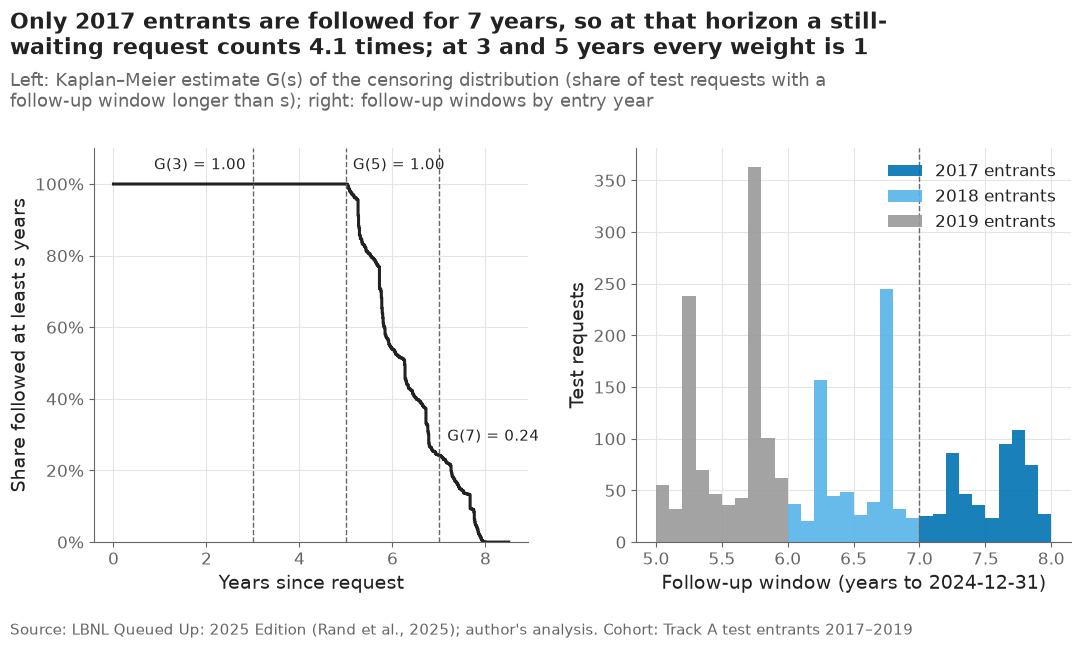

In [4]:
G = evaluation.censoring_km(follow_up, np.ones(len(test), dtype=bool))
weights = {h: evaluation.horizon_outcome(durations, events, h, G)[1] for h in HORIZONS}
for h in HORIZONS:
    w = weights[h]
    print(f"{h} yr: G({h}) = {float(G(h)):.3f}; weights equal to 1: {np.mean(w == 1):.1%}; zero: {int((w == 0).sum())}; "
          f"largest {w.max():.2f}")

fig, axes = plt.subplots(1, 2)
grid = np.linspace(0, 8.5, 851)
axes[0].step(grid, G(grid), where="post", color=plots.INK)
for h in HORIZONS:
    axes[0].axvline(h, color=plots.MUTED, linewidth=1, linestyle="--")
    dx, ha = {3: (-5, "right"), 5: (5, "left"), 7: (6, "left")}[h]  # labels on either side of their line, clear of the curve
    axes[0].annotate(f"G({h}) = {float(G(h)):.2f}", (h, float(G(h))), xytext=(dx, 8), textcoords="offset points",
                     ha=ha, va="bottom", fontsize=11)
axes[0].set_xlabel("Years since request")
axes[0].set_ylabel("Share followed at least s years")
axes[0].set_ylim(0, 1.1)
axes[0].yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
year_shades = {2017: "#0072B2", 2018: "#56B4E9", 2019: "#999999"}
for year, color in year_shades.items():
    axes[1].hist(follow_up[test["q_year"].to_numpy() == year], bins=np.arange(5, 8.01, 0.1), color=color, alpha=0.9,
                 label=f"{year} entrants")
axes[1].axvline(7, color=plots.MUTED, linewidth=1, linestyle="--")
axes[1].set_xlabel("Follow-up window (years to 2024-12-31)")
axes[1].set_ylabel("Test requests")
axes[1].legend(loc="upper right")
plots.finish(fig,
             f"Only 2017 entrants are followed for 7 years, so at that horizon a still-waiting request counts "
             f"{1 / float(G(7)):.1f} times; at 3 and 5 years every weight is 1",
             "Left: Kaplan–Meier estimate G(s) of the censoring distribution (share of test requests with a follow-up "
             "window longer than s); right: follow-up windows by entry year",
             "Track A test entrants 2017–2019")
save(fig, "08_02_censoring_weights", "Censoring distribution of the test cohort and follow-up windows by entry year.")
plt.show()

**Reading this.** G(3) = G(5) = 1.000, so every weight is 1 at 3 and 5 years and those metrics are plain proportions. G(7) = 0.242: only the 2017 entrants are followed for seven years, so a request still waiting at year 7 counts 1/0.242 = 4.13 times, while 532 censored requests count zero and 64.9% of weights stay at 1 (exits before year 5). The 7-year numbers therefore depend heavily on 549 requests from one entry year; section 7 checks them on those requests alone.

## 2. Discrimination and overall accuracy

For each horizon, all four models are scored on the same requests:
Uno's and Harrell's concordance (does a request that operated earlier have a
higher prediction than one that operated later, was still waiting, or had
withdrawn?), time-dependent AUC (operated by t vs not), the IPCW Brier score,
the calibration slope and intercept, and precision and lift in the top 10%.
Intervals come from 200 bootstrap resamples of test requests with the
registered seed; the same resamples score every model, so model − baseline
differences are paired.

In [5]:
metric_tables, draws_by_h = [], {}
for h in HORIZONS:
    point = evaluation.score_horizon(preds[h], durations, events, h, G)
    draws = evaluation.bootstrap(lambda sw: evaluation.score_horizon(preds[h], durations, events, h, G, sw),
                                 len(test), N_BOOT, REGISTERED["seed_track_a"])
    table = evaluation.summarise(point, draws, level=LEVEL)
    table.insert(2, "horizon", h)
    metric_tables.append(table)
    draws_by_h[h] = draws
metrics_a = pd.concat(metric_tables, ignore_index=True)
metrics_a.insert(0, "track", "A")
print(f"bootstrap done in {(time.time() - START) / 60:.1f} minutes since the start")
show = metrics_a[metrics_a["metric"].isin(["uno_c", "harrell_c", "auc", "brier"])].copy()
show["value"] = [f"{r.estimate:.3f} [{r.low:.3f}, {r.high:.3f}]" for r in show.itertuples()]
show.pivot_table(index=["metric", "horizon"], columns="model", values="value", aggfunc="first")[MODELS]

bootstrap done in 0.7 minutes since the start


model                          baseline                   cox              dt_logit               dt_lgbm
metric    horizon                                                                                        
auc       3        0.733 [0.678, 0.784]  0.852 [0.817, 0.882]  0.836 [0.796, 0.871]  0.858 [0.824, 0.893]
          5        0.725 [0.690, 0.761]  0.765 [0.735, 0.795]  0.751 [0.717, 0.779]  0.766 [0.736, 0.799]
          7        0.654 [0.617, 0.686]  0.696 [0.662, 0.726]  0.668 [0.630, 0.700]  0.672 [0.629, 0.703]
brier     3        0.047 [0.041, 0.054]  0.044 [0.038, 0.051]  0.042 [0.036, 0.049]  0.041 [0.035, 0.048]
          5        0.086 [0.079, 0.094]  0.081 [0.073, 0.089]  0.081 [0.073, 0.090]  0.081 [0.074, 0.089]
          7        0.122 [0.112, 0.132]  0.118 [0.108, 0.129]  0.121 [0.112, 0.133]  0.121 [0.113, 0.133]
harrell_c 3        0.731 [0.678, 0.781]  0.847 [0.814, 0.876]  0.832 [0.793, 0.866]  0.853 [0.820, 0.886]
          5        0.719 [0.684, 0.755]  0.760 [0.731, 0.789]  0.746 [0.715, 0.773]  0.760 [0.731, 0.791]
          7        0.671 [0.635, 0.701]  0.724 [0.695, 0.751]  0.699 [0.668, 0.724]  0.697 [0.668, 0.722]
uno_c     3        0.731 [0.678, 0.781]  0.847 [0.814, 0.876]  0.832 [0.793, 0.866]  0.853 [0.820, 0.886]
          5        0.719 [0.684, 0.755]  0.760 [0.731, 0.789]  0.746 [0.715, 0.773]  0.760 [0.731, 0.791]
          7        0.657 [0.623, 0.684]  0.703 [0.672, 0.731]  0.681 [0.648, 0.706]  0.672 [0.637, 0.700]

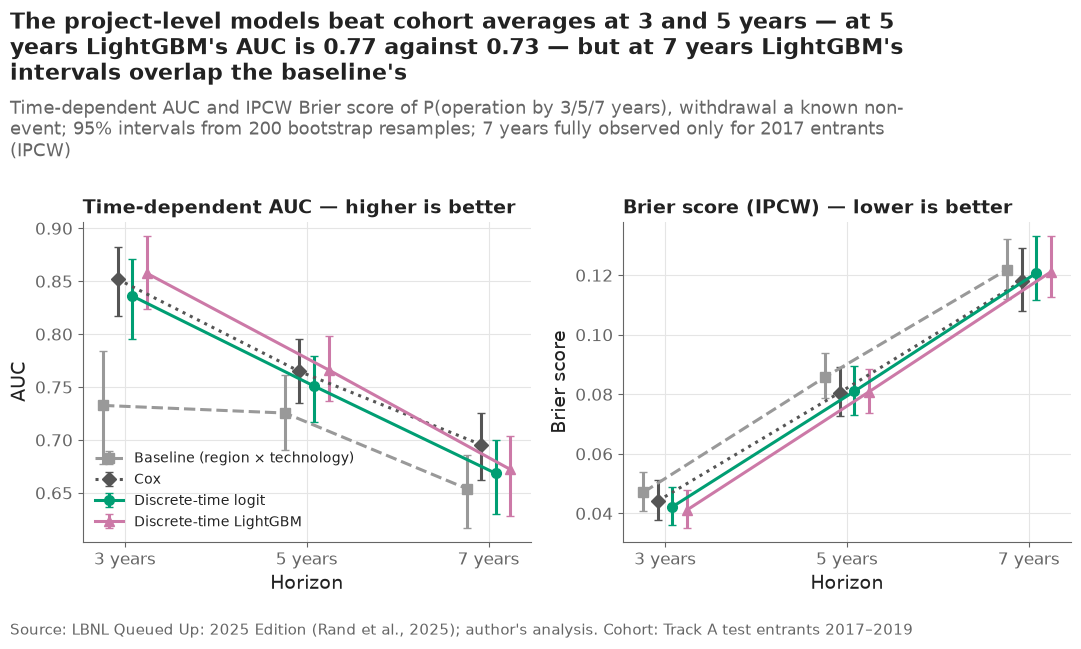

In [6]:
fig, axes = plt.subplots(1, 2, sharex=True)
for ax, metric in zip(axes, ["auc", "brier"]):
    for model in MODELS:
        part = metrics_a[(metrics_a["model"] == model) & (metrics_a["metric"] == metric)]
        errorbars(ax, part["horizon"] + OFFSETS[model], part, label=MODEL_LABELS[model], **MODEL_STYLE[model])
    ax.set_xticks(HORIZONS, [f"{h} years" for h in HORIZONS])
    ax.set_xlabel("Horizon")
    ax.set_title(METRIC_LABELS[metric] + (" — higher is better" if metric == "auc" else " — lower is better"))
axes[0].set_ylabel("AUC")
axes[1].set_ylabel("Brier score")
axes[0].legend(loc="lower left", fontsize=10)
plots.finish(fig,
             "The project-level models beat cohort averages at 3 and 5 years — at 5 years LightGBM's AUC is "
             f"{value(metrics_a, 'dt_lgbm', 'auc', 5):.2f} against {value(metrics_a, 'baseline', 'auc', 5):.2f} — but at 7 "
             "years LightGBM's intervals overlap the baseline's",
             "Time-dependent AUC and IPCW Brier score of P(operation by 3/5/7 years), withdrawal a known non-event; "
             "95% intervals from 200 bootstrap resamples; 7 years fully observed only for 2017 entrants (IPCW)",
             "Track A test entrants 2017–2019")
plots.save_fig(fig, "F5_auc_brier_by_horizon", "Time-dependent AUC and IPCW Brier score of the four Track A models at 3, 5 and 7 years, test cohort, with bootstrap intervals.", NOTEBOOK)
plt.show()

**Reading this.** At 3 years the discrete-time LightGBM's time-dependent AUC is 0.858 [0.824, 0.893] against 0.733 [0.678, 0.784] for the region × technology baseline; at 5 years 0.766 [0.736, 0.799] against 0.725 [0.690, 0.761]; at 7 years 0.672 [0.629, 0.703] against 0.654 [0.617, 0.686]. The Brier scores move the same way (0.041 vs 0.047, 0.081 vs 0.086, 0.121 vs 0.122). Two things follow. Project-level information adds most for the near term: who reaches operation within 3 years is well predicted at entry; who does so by year 7 much less. And the Brier differences are small in absolute terms because most requests never operate, so a predictor that says "low" for everyone is already close; the gains are judged by the paired intervals in the next cells, not by eye. Cox is as good as LightGBM at 3 and 5 years (AUC 0.852 and 0.765) and the best model at 7 years (0.696; Brier 0.118). Caveat: the 7-year values are IPCW estimates driven by 2017 entrants (previous cell).

Uno − Harrell for LightGBM: {3: np.float64(0.0), 5: np.float64(0.0), 7: np.float64(-0.0245)}


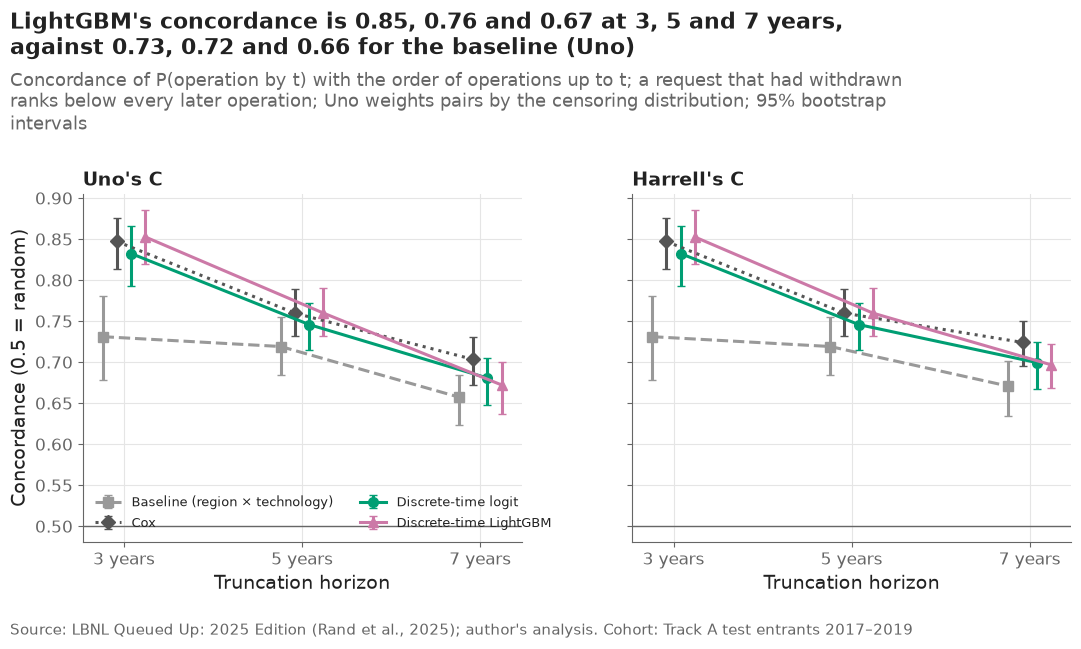

In [7]:
fig, axes = plt.subplots(1, 2, sharey=True)
for ax, metric in zip(axes, ["uno_c", "harrell_c"]):
    for model in MODELS:
        part = metrics_a[(metrics_a["model"] == model) & (metrics_a["metric"] == metric)]
        errorbars(ax, part["horizon"] + OFFSETS[model], part, label=MODEL_LABELS[model], **MODEL_STYLE[model])
    ax.axhline(0.5, color=plots.MUTED, linewidth=1)
    ax.set_xticks(HORIZONS, [f"{h} years" for h in HORIZONS])
    ax.set_xlabel("Truncation horizon")
    ax.set_title(METRIC_LABELS[metric])
axes[0].set_ylabel("Concordance (0.5 = random)")
axes[0].legend(loc="lower left", fontsize=9.5, ncol=2)
gap = {h: value(metrics_a, "dt_lgbm", "uno_c", h) - value(metrics_a, "dt_lgbm", "harrell_c", h) for h in HORIZONS}
print("Uno − Harrell for LightGBM:", {h: round(g, 4) for h, g in gap.items()})
plots.finish(fig,
             f"LightGBM's concordance is {value(metrics_a, 'dt_lgbm', 'uno_c', 3):.2f}, "
             f"{value(metrics_a, 'dt_lgbm', 'uno_c', 5):.2f} and {value(metrics_a, 'dt_lgbm', 'uno_c', 7):.2f} at 3, 5 and 7 "
             f"years, against {value(metrics_a, 'baseline', 'uno_c', 3):.2f}, {value(metrics_a, 'baseline', 'uno_c', 5):.2f} "
             f"and {value(metrics_a, 'baseline', 'uno_c', 7):.2f} for the baseline (Uno)",
             "Concordance of P(operation by t) with the order of operations up to t; a request that had withdrawn ranks "
             "below every later operation; Uno weights pairs by the censoring distribution; 95% bootstrap intervals",
             "Track A test entrants 2017–2019")
save(fig, "08_03_concordance", "Uno's and Harrell's concordance of the four Track A models by horizon, with bootstrap intervals.")
plt.show()

**Reading this.** With no censoring before year 5, Uno's and Harrell's concordance are identical at 3 and 5 years (0.853 and 0.760 for LightGBM, 0.731 and 0.719 for the baseline). At 7 years Uno's weighting lowers LightGBM's value by 0.0245 (to 0.672) and the baseline's to 0.657, while Cox keeps 0.703: the weighted pairs are the 2017 entrants' late operations, which LightGBM ranks less well. Concordance reads as the chance that, of two requests where one operated first, the model gave that one the higher score: about 85% at 3 years, 76% at 5, 67% at 7.

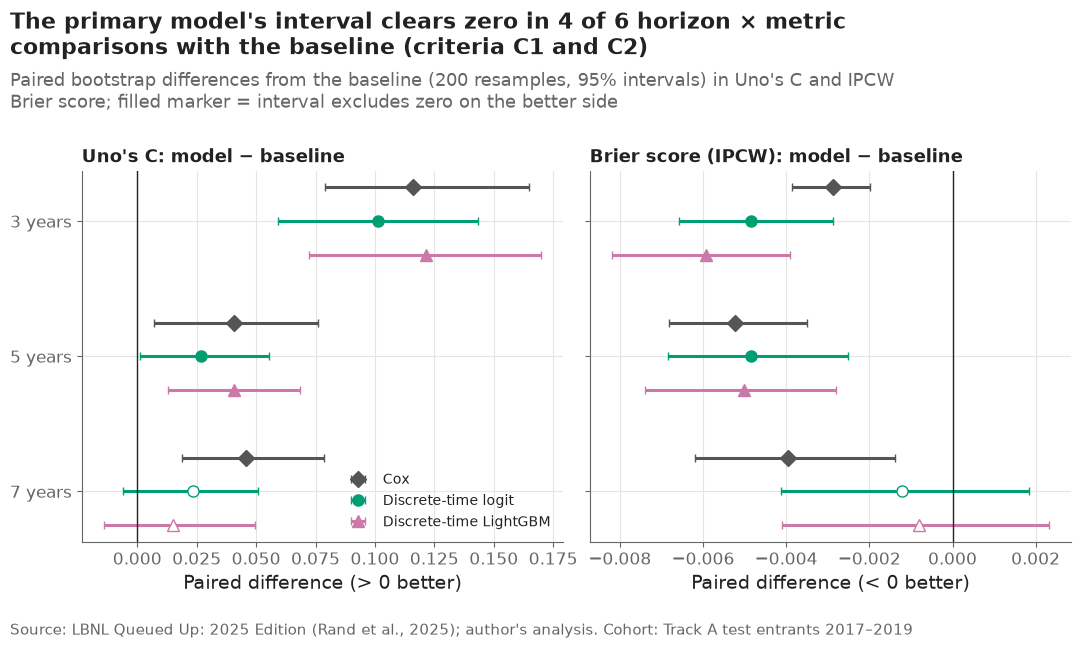

model                               cox                 dt_logit                  dt_lgbm
metric horizon                                                                           
auc    3        +0.119 [+0.080, +0.169]  +0.103 [+0.061, +0.147]  +0.125 [+0.073, +0.174]
       5        +0.039 [+0.006, +0.075]  +0.026 [-0.001, +0.055]  +0.041 [+0.013, +0.069]
       7        +0.042 [+0.008, +0.077]  +0.014 [-0.020, +0.048]  +0.018 [-0.016, +0.060]
brier  3        -0.003 [-0.004, -0.002]  -0.005 [-0.007, -0.003]  -0.006 [-0.008, -0.004]
       5        -0.005 [-0.007, -0.004]  -0.005 [-0.007, -0.003]  -0.005 [-0.007, -0.003]
       7        -0.004 [-0.006, -0.001]  -0.001 [-0.004, +0.002]  -0.001 [-0.004, +0.002]
uno_c  3        +0.116 [+0.079, +0.165]  +0.101 [+0.059, +0.143]  +0.121 [+0.072, +0.170]
       5        +0.041 [+0.007, +0.076]  +0.027 [+0.001, +0.055]  +0.041 [+0.013, +0.069]
       7        +0.046 [+0.019, +0.079]  +0.023 [-0.006, +0.051]  +0.015 [-0.014, +0.050]

In [8]:
fig, axes = plt.subplots(1, 2, sharey=True)
compared = ["cox", "dt_logit", "dt_lgbm"]
for ax, metric in zip(axes, ["uno_c", "brier"]):
    for h_i, h in enumerate(HORIZONS):
        for m_i, model in enumerate(compared):
            row = metrics_a[(metrics_a["model"] == model) & (metrics_a["metric"] == metric) & (metrics_a["horizon"] == h)].iloc[0]
            y = h_i * (len(compared) + 1) + m_i
            style = MODEL_STYLE[model]
            ax.errorbar(row["diff"], y, xerr=[[row["diff"] - row["diff_low"]], [row["diff_high"] - row["diff"]]],
                        fmt=style["marker"], color=style["color"], capsize=3, markersize=8,
                        markerfacecolor=style["color"] if row["beats"] else "white",
                        label=MODEL_LABELS[model] if h_i == 0 else None)
    ax.axvline(0, color=plots.INK, linewidth=1)
    ax.set_title(f"{METRIC_LABELS[metric]}: model − baseline", fontsize=13)
    ax.set_xlabel("Paired difference (" + ("> 0 better" if metric == "uno_c" else "< 0 better") + ")")
centres = [h_i * (len(compared) + 1) + 1 for h_i in range(len(HORIZONS))]
axes[0].set_yticks(centres, [f"{h} years" for h in HORIZONS])
axes[0].invert_yaxis()
axes[0].legend(loc="lower right", fontsize=10)
beats = metrics_a[(metrics_a["model"] == "dt_lgbm") & metrics_a["metric"].isin(["uno_c", "brier"])]
plots.finish(fig,
             f"The primary model's interval clears zero in {int(beats['beats'].sum())} of 6 horizon × metric comparisons "
             "with the baseline (criteria C1 and C2)",
             "Paired bootstrap differences from the baseline (200 resamples, 95% intervals) in Uno's C and IPCW Brier "
             "score; filled marker = interval excludes zero on the better side",
             "Track A test entrants 2017–2019")
save(fig, "08_04_differences_from_baseline", "Paired differences from the baseline in Uno's concordance and Brier score, three models, three horizons.")
plt.show()
d = metrics_a[metrics_a["diff"].notna() & metrics_a["metric"].isin(["uno_c", "auc", "brier"])].copy()
d["difference"] = [f"{r.diff:+.3f} [{r.diff_low:+.3f}, {r.diff_high:+.3f}]" for r in d.itertuples()]
d.pivot_table(index=["metric", "horizon"], columns="model", values="difference", aggfunc="first")[compared]

**Reading this.** Paired with the baseline on the same resamples, LightGBM's gain in Uno's C is +0.121 [+0.072, +0.170] at 3 years and +0.041 [+0.013, +0.069] at 5 years, and its Brier score is lower by 0.006 [0.004, 0.008] and 0.005 [0.003, 0.007]: both intervals exclude zero at 3 and 5 years. At 7 years the intervals include zero (Uno +0.015 [−0.014, +0.050]; Brier −0.001 [−0.004, +0.002]), so criteria C1 and C2 fail there. Cox, which decides nothing in the criteria, beats the baseline at all three horizons on both metrics (at 7 years Uno +0.046 [+0.019, +0.079], Brier −0.004 [−0.006, −0.001]). For the report this is the main ranking result: the primary model adds clear value over cohort averages for 3- and 5-year screening, and its late-horizon edge is not established.

### Within each region

Most of the baseline's ranking power is region: CAISO requests rarely
operate, ERCOT requests often do. Within one region the baseline can only
rank by technology. The same metrics computed inside each region (each with
its own censoring distribution and the same 200 resamples) show whether the
models rank requests beyond knowing their region.

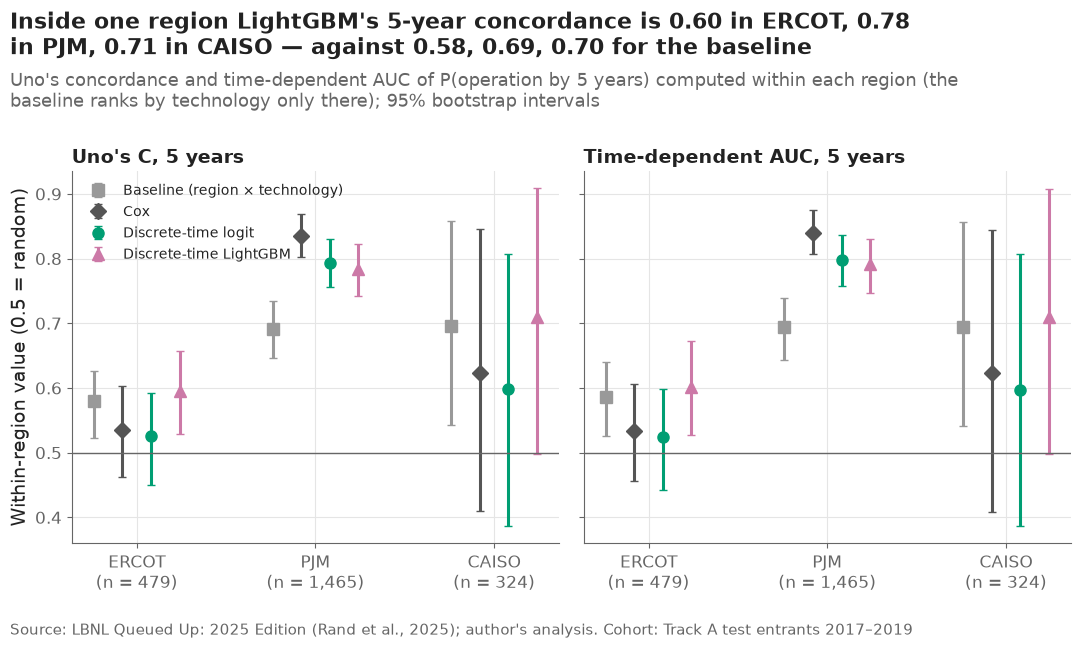

model                              baseline                   cox              dt_logit               dt_lgbm
region metric horizon                                                                                        
CAISO  auc    3        0.884 [0.802, 0.957]  0.852 [0.596, 1.000]  0.873 [0.686, 1.000]  0.970 [0.904, 1.000]
              5        0.694 [0.541, 0.857]  0.623 [0.408, 0.845]  0.597 [0.386, 0.807]  0.709 [0.498, 0.908]
              7        0.540 [0.389, 0.719]  0.567 [0.394, 0.766]  0.508 [0.340, 0.669]  0.614 [0.438, 0.788]
       brier  3        0.015 [0.003, 0.029]  0.014 [0.003, 0.027]  0.015 [0.003, 0.029]  0.013 [0.003, 0.025]
              5        0.030 [0.015, 0.049]  0.029 [0.015, 0.047]  0.029 [0.014, 0.048]  0.027 [0.013, 0.044]
              7        0.043 [0.023, 0.066]  0.042 [0.023, 0.065]  0.042 [0.023, 0.066]  0.041 [0.023, 0.062]
       uno_c  3        0.883 [0.801, 0.957]  0.851 [0.595, 1.000]  0.872 [0.684, 1.000]  0.968 [0.903, 1.000]
              5        0.695 [0.543, 0.858]  0.624 [0.409, 0.845]  0.598 [0.386, 0.807]  0.709 [0.498, 0.909]
              7        0.555 [0.393, 0.721]  0.596 [0.413, 0.776]  0.558 [0.385, 0.714]  0.627 [0.445, 0.796]
ERCOT  auc    3        0.582 [0.474, 0.664]  0.605 [0.490, 0.715]  0.605 [0.484, 0.716]  0.576 [0.439, 0.697]
              5        0.586 [0.525, 0.641]  0.533 [0.455, 0.607]  0.525 [0.442, 0.598]  0.602 [0.528, 0.672]
              7        0.562 [0.497, 0.634]  0.510 [0.426, 0.597]  0.495 [0.404, 0.580]  0.520 [0.436, 0.594]
       brier  3        0.053 [0.038, 0.070]  0.054 [0.040, 0.071]  0.057 [0.042, 0.077]  0.057 [0.043, 0.076]
              5        0.137 [0.115, 0.156]  0.141 [0.117, 0.162]  0.145 [0.122, 0.166]  0.140 [0.118, 0.159]
              7        0.162 [0.138, 0.184]  0.167 [0.137, 0.195]  0.171 [0.144, 0.197]  0.170 [0.145, 0.192]
       uno_c  3        0.583 [0.479, 0.661]  0.601 [0.488, 0.707]  0.602 [0.484, 0.715]  0.575 [0.439, 0.693]
              5        0.579 [0.523, 0.627]  0.534 [0.462, 0.603]  0.526 [0.450, 0.592]  0.596 [0.529, 0.656]
              7        0.582 [0.533, 0.633]  0.500 [0.423, 0.578]  0.498 [0.427, 0.570]  0.601 [0.539, 0.651]
PJM    auc    3        0.753 [0.694, 0.809]  0.915 [0.887, 0.941]  0.907 [0.881, 0.931]  0.906 [0.875, 0.934]
              5        0.694 [0.644, 0.738]  0.840 [0.808, 0.875]  0.798 [0.758, 0.837]  0.792 [0.747, 0.830]
              7        0.618 [0.576, 0.654]  0.732 [0.694, 0.769]  0.673 [0.632, 0.723]  0.654 [0.603, 0.704]
       brier  3        0.052 [0.046, 0.063]  0.048 [0.040, 0.059]  0.044 [0.037, 0.053]  0.042 [0.036, 0.051]
              5        0.081 [0.074, 0.092]  0.072 [0.064, 0.083]  0.072 [0.063, 0.083]  0.073 [0.065, 0.084]
              7        0.126 [0.113, 0.140]  0.119 [0.106, 0.133]  0.121 [0.107, 0.136]  0.123 [0.110, 0.137]
       uno_c  3        0.749 [0.693, 0.804]  0.908 [0.882, 0.933]  0.899 [0.874, 0.924]  0.897 [0.869, 0.924]
              5        0.691 [0.646, 0.734]  0.835 [0.802, 0.868]  0.793 [0.756, 0.830]  0.784 [0.742, 0.823]
              7        0.623 [0.585, 0.658]  0.753 [0.718, 0.787]  0.696 [0.658, 0.739]  0.639 [0.593, 0.687]

In [9]:
region_tables = []
for r_i, region in enumerate(TRACK_A):
    mask = regions == region
    G_r = evaluation.censoring_km(follow_up[mask], np.ones(mask.sum(), dtype=bool))
    for h in HORIZONS:
        sub = {m: preds[h][m][mask] for m in MODELS}
        point = evaluation.score_horizon(sub, durations[mask], events[mask], h, G_r)
        draws = evaluation.bootstrap(lambda sw: evaluation.score_horizon(sub, durations[mask], events[mask], h, G_r, sw),
                                     int(mask.sum()), N_BOOT, REGISTERED["seed_track_a"] + 10 + r_i)
        table = evaluation.summarise(point, draws, level=LEVEL)
        table.insert(0, "region", region)
        table.insert(3, "horizon", h)
        region_tables.append(table)
metrics_region = pd.concat(region_tables, ignore_index=True)
metrics_region.to_csv(paths.RESULTS / "metrics_by_region.csv", index=False)

fig, axes = plt.subplots(1, 2, sharey=True)
for ax, metric in zip(axes, ["uno_c", "auc"]):
    for model in MODELS:
        part = metrics_region[(metrics_region["model"] == model) & (metrics_region["metric"] == metric)
                              & (metrics_region["horizon"] == 5)]
        x = np.arange(len(TRACK_A)) + OFFSETS[model]
        errorbars(ax, x, part.set_index("region").loc[TRACK_A], fmt=MODEL_STYLE[model]["marker"],
                  color=MODEL_STYLE[model]["color"], markersize=8, label=MODEL_LABELS[model])
    ax.axhline(0.5, color=plots.MUTED, linewidth=1)
    ax.set_xticks(range(len(TRACK_A)), [f"{r}\n(n = {(regions == r).sum():,})" for r in TRACK_A])
    ax.set_title(f"{METRIC_LABELS[metric]}, 5 years")
axes[0].set_ylabel("Within-region value (0.5 = random)")
axes[0].legend(loc="upper left", fontsize=10)
within = metrics_region[(metrics_region["metric"] == "uno_c") & (metrics_region["horizon"] == 5)].set_index(["region", "model"])["estimate"]
plots.finish(fig,
             "Inside one region LightGBM's 5-year concordance is "
             + ", ".join(f"{within[(r, 'dt_lgbm')]:.2f} in {r}" for r in TRACK_A)
             + " — against " + ", ".join(f"{within[(r, 'baseline')]:.2f}" for r in TRACK_A) + " for the baseline",
             "Uno's concordance and time-dependent AUC of P(operation by 5 years) computed within each region "
             "(the baseline ranks by technology only there); 95% bootstrap intervals",
             "Track A test entrants 2017–2019")
save(fig, "08_05_within_region", "Within-region concordance and AUC at 5 years for the four Track A models.")
plt.show()
w = metrics_region[metrics_region["metric"].isin(["uno_c", "auc", "brier"])].copy()
w["value"] = [f"{r.estimate:.3f} [{r.low:.3f}, {r.high:.3f}]" for r in w.itertuples()]
w.pivot_table(index=["region", "metric", "horizon"], columns="model", values="value", aggfunc="first")[MODELS]

**Reading this.** Inside PJM, LightGBM's 5-year concordance is 0.784 [0.742, 0.823] against the baseline's 0.691 [0.646, 0.734] — a real gain where the baseline can only rank by technology (Cox does better still, 0.835). Inside ERCOT the models barely rank at all: LightGBM 0.596 [0.529, 0.656] against 0.579 [0.523, 0.627], with Cox (0.534) and the logit (0.526) near random — ERCOT's training data under delayed entry are thin (98 of 732 training requests in notebook 06). CAISO's intervals are too wide to say anything (10 operations within 5 years; LightGBM 0.709 [0.498, 0.909]). So most of the pooled gain comes from ranking within PJM, plus getting the regions in the right order, which the baseline also does.

## 3. Calibration

Can a predicted 20% be read as a 20% chance? Test requests are cut into ten
equal groups by each model's prediction; in each group the mean prediction is
set against the Aalen–Johansen estimate of P(operation by t) (which handles
the censored requests at 7 years) with a 200-resample bootstrap band. The
calibration slope and intercept summarise the same picture: slope 1 and
intercept 0 are perfect; a slope below 1 means the predictions are too
spread out, an intercept above 0 that they are too low on average.

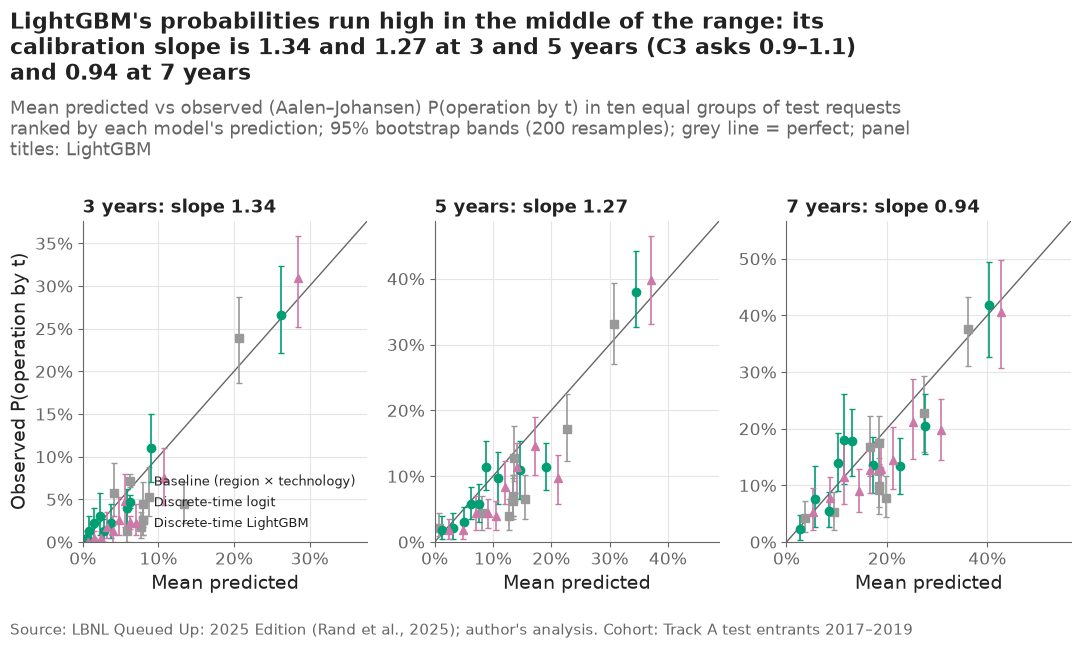

observed               predicted              
horizon        3      5      7         3      5      7
decile                                                
1          0.000  0.018  0.054     0.006  0.024  0.052
2          0.004  0.018  0.078     0.015  0.049  0.087
3          0.004  0.044  0.114     0.024  0.071  0.114
4          0.018  0.044  0.090     0.032  0.091  0.145
5          0.013  0.040  0.127     0.040  0.106  0.166
6          0.026  0.084  0.129     0.047  0.121  0.188
7          0.048  0.115  0.144     0.056  0.142  0.212
8          0.022  0.145  0.213     0.070  0.171  0.252
9          0.075  0.097  0.198     0.108  0.212  0.308
10         0.310  0.398  0.406     0.285  0.371  0.428

In [10]:
cal_rows = []
for h in HORIZONS:
    for m_i, model in enumerate(MODELS):
        groups = evaluation.decile_groups(preds[h][model])
        for g in range(10):
            idx = groups == g
            observed = survival_tools.aalen_johansen(durations[idx], events[idx], [h])["cif_operation"].iloc[0]
            band = survival_tools.bootstrap_bands(durations[idx], events[idx], [h], n_boot=N_BOOT, seed=810 + 10 * m_i + g)
            cal_rows.append({"horizon": h, "model": model, "decile": g + 1, "n": int(idx.sum()),
                             "predicted": preds[h][model][idx].mean(), "observed": observed,
                             "low": band["cif_operation_low"].iloc[0], "high": band["cif_operation_high"].iloc[0]})
calibration = pd.DataFrame(cal_rows)
calibration.to_csv(paths.RESULTS / "calibration.csv", index=False)

shown = ["baseline", "dt_logit", "dt_lgbm"]
fig, axes = plt.subplots(1, 3)
for ax, h in zip(axes, HORIZONS):
    part_h = calibration[calibration["horizon"] == h]
    top = max(part_h["high"].max(), part_h["predicted"].max()) * 1.05
    ax.plot([0, top], [0, top], color=plots.MUTED, linewidth=1)
    for model in shown:
        part = part_h[part_h["model"] == model]
        style = MODEL_STYLE[model]
        ax.errorbar(part["predicted"], part["observed"], yerr=[part["observed"] - part["low"], part["high"] - part["observed"]],
                    fmt=style["marker"], color=style["color"], capsize=2, markersize=6, linewidth=1.2,
                    label=MODEL_LABELS[model])
    ax.set_xlim(0, top)
    ax.set_ylim(0, top)
    ax.set_title(f"{h} years: slope {value(metrics_a, 'dt_lgbm', 'slope', h):.2f}", fontsize=13)
    ax.set_xlabel("Mean predicted")
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[0].set_ylabel("Observed P(operation by t)")
axes[0].legend(loc="lower right", fontsize=9.5)
plots.finish(fig,
             "LightGBM's probabilities run high in the middle of the range: its calibration slope is "
             f"{value(metrics_a, 'dt_lgbm', 'slope', 3):.2f} and {value(metrics_a, 'dt_lgbm', 'slope', 5):.2f} at 3 and 5 years "
             f"(C3 asks 0.9–1.1) and {value(metrics_a, 'dt_lgbm', 'slope', 7):.2f} at 7 years",
             "Mean predicted vs observed (Aalen–Johansen) P(operation by t) in ten equal groups of test requests ranked by "
             "each model's prediction; 95% bootstrap bands (200 resamples); grey line = perfect; panel titles: LightGBM",
             "Track A test entrants 2017–2019")
plots.save_fig(fig, "F4_calibration_by_horizon", "Calibration of P(operation by 3, 5 and 7 years) by predicted decile: baseline, discrete-time logit and LightGBM, test cohort.", NOTEBOOK)
plt.show()
calibration[calibration["model"] == "dt_lgbm"].pivot_table(index="decile", columns="horizon", values=["predicted", "observed"]).round(3)

**Reading this.** Ranked into ten equal groups, LightGBM's top group is well calibrated at 5 years (37.1% predicted, 39.8% observed), but the groups in the middle are predicted too high: the 5th group 10.6% predicted vs 4.0% observed, the 9th 21.2% vs 9.7%. Its calibration slope is 1.34 [1.15, 1.58] at 3 years and 1.27 [1.11, 1.49] at 5 years — the observed outcomes separate more sharply than the predictions — and 0.94 [0.72, 1.14] at 7 years. Criterion C3 (slope 0.9–1.1) therefore passes only at 7 years. For a lender this means LightGBM's middle-of-the-range probabilities should not be taken at face value: a predicted 20% was closer to 10% in this cohort. The ranking (previous section) is more trustworthy than the level.

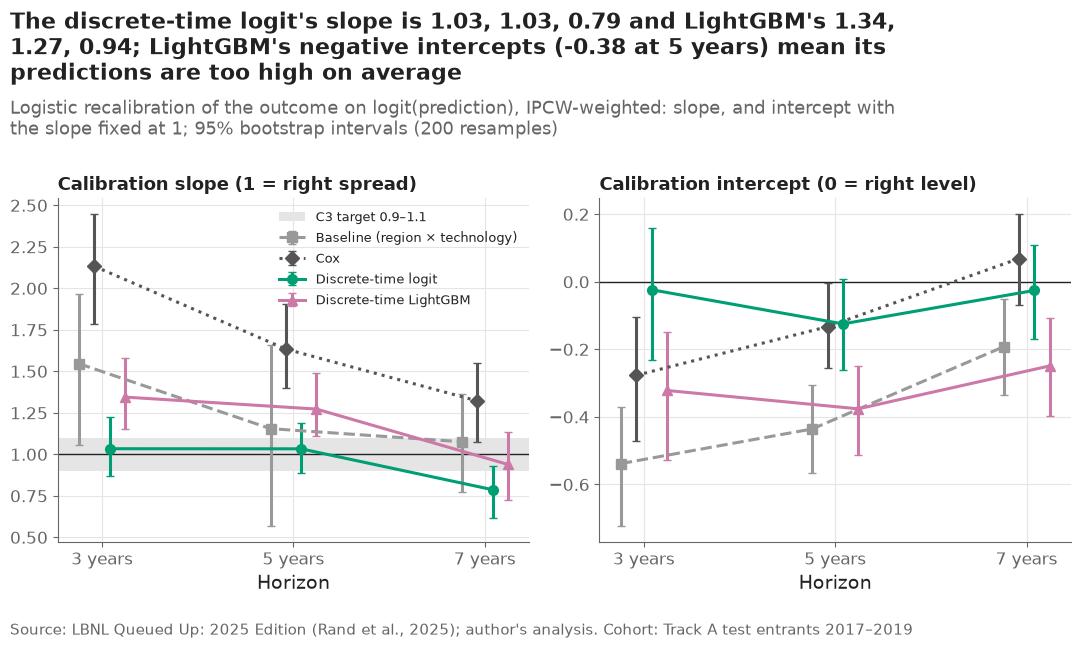

model              baseline   cox  dt_logit  dt_lgbm
metric    horizon                                   
intercept 3           -0.54 -0.28     -0.02    -0.32
          5           -0.44 -0.13     -0.12    -0.38
          7           -0.19  0.07     -0.03    -0.25
slope     3            1.55  2.13      1.03     1.34
          5            1.15  1.63      1.03     1.27
          7            1.08  1.32      0.79     0.94

In [11]:
fig, axes = plt.subplots(1, 2, sharex=True)
for ax, metric, target in zip(axes, ["slope", "intercept"], [1.0, 0.0]):
    if metric == "slope":
        ax.axhspan(0.9, 1.1, color="#E5E5E5", label="C3 target 0.9–1.1")
    ax.axhline(target, color=plots.INK, linewidth=1)
    for model in MODELS:
        part = metrics_a[(metrics_a["model"] == model) & (metrics_a["metric"] == metric)]
        errorbars(ax, part["horizon"] + OFFSETS[model], part, label=MODEL_LABELS[model], **MODEL_STYLE[model])
    ax.set_xticks(HORIZONS, [f"{h} years" for h in HORIZONS])
    ax.set_xlabel("Horizon")
    ax.set_title(METRIC_LABELS[metric] + (" (1 = right spread)" if metric == "slope" else " (0 = right level)"), fontsize=13)
axes[0].legend(loc="best", fontsize=9.5)
plots.finish(fig,
             "The discrete-time logit's slope is "
             + ", ".join(f"{value(metrics_a, 'dt_logit', 'slope', h):.2f}" for h in HORIZONS)
             + " and LightGBM's " + ", ".join(f"{value(metrics_a, 'dt_lgbm', 'slope', h):.2f}" for h in HORIZONS)
             + f"; LightGBM's negative intercepts ({value(metrics_a, 'dt_lgbm', 'intercept', 5):.2f} at 5 years) mean its "
             "predictions are too high on average",
             "Logistic recalibration of the outcome on logit(prediction), IPCW-weighted: slope, and intercept with the "
             "slope fixed at 1; 95% bootstrap intervals (200 resamples)",
             "Track A test entrants 2017–2019")
save(fig, "08_06_calibration_slope_intercept", "Calibration slope and intercept of the four Track A models by horizon.")
plt.show()
metrics_a[metrics_a["metric"].isin(["slope", "intercept"])].pivot_table(
    index=["metric", "horizon"], columns="model", values="estimate")[MODELS].round(2)

**Reading this.** The discrete-time logit is the best calibrated model at 3 and 5 years: slope 1.03 at both, intercept −0.02 and −0.12, inside C3's band. It is not the primary model, so this decides nothing in the criteria, but it matters for which model's probabilities a user should quote. LightGBM's slopes are 1.34, 1.27 and 0.94 with intercepts −0.32, −0.38 and −0.25: its predictions are too high on average and too compressed at 3 and 5 years. Cox has the steepest slopes (2.13, 1.63, 1.32), so its probabilities are the most compressed although it ranks best at 7 years; the baseline's slopes are 1.55, 1.15 and 1.08 with intercepts −0.54, −0.44 and −0.19. At 7 years the logit's slope falls to 0.79, too spread out. The pattern suggests that ranking and level are best taken from different models — a possibility for a labelled post-hoc analysis, not something to change in the registered evaluation.

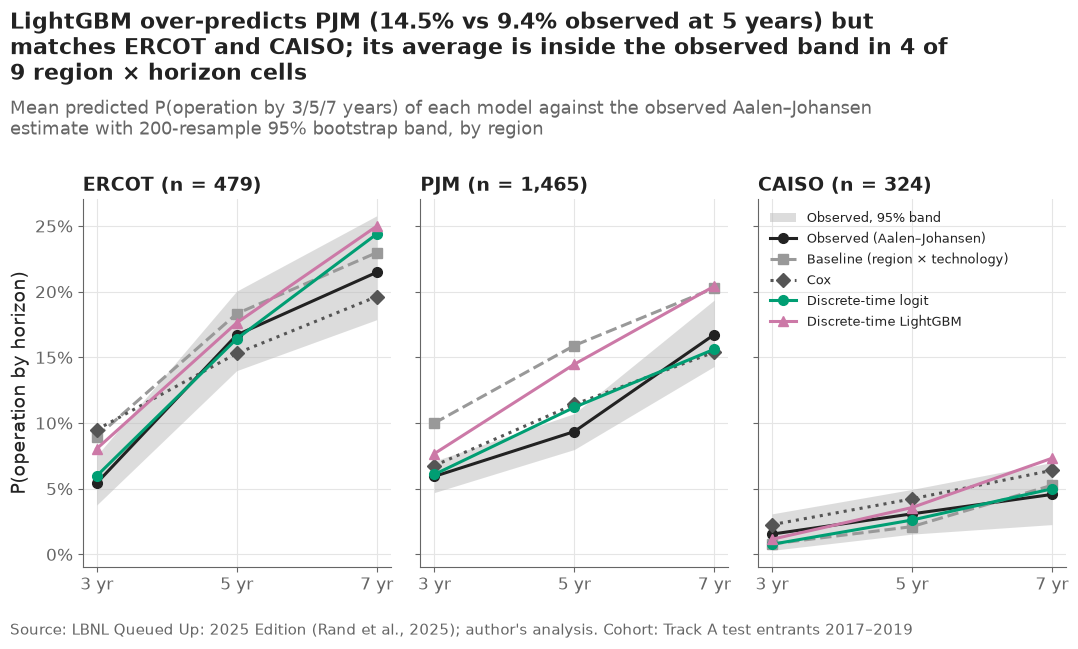

,region,n,horizon,observed,low,high,baseline,cox,dt_logit,dt_lgbm
0,ERCOT,479,3,0.054,0.038,0.075,0.090,0.095,0.060,0.080
1,ERCOT,479,5,0.167,0.140,0.200,0.183,0.153,0.164,0.176
2,ERCOT,479,7,0.215,0.179,0.258,0.230,0.196,0.244,0.250
3,PJM,1465,3,0.059,0.047,0.071,0.100,0.068,0.061,0.077
4,PJM,1465,5,0.094,0.080,0.107,0.159,0.114,0.112,0.145
5,PJM,1465,7,0.167,0.143,0.194,0.203,0.154,0.156,0.204
6,CAISO,324,3,0.015,0.003,0.031,0.008,0.023,0.008,0.012
7,CAISO,324,5,0.031,0.015,0.049,0.021,0.042,0.026,0.036
8,CAISO,324,7,0.046,0.023,0.070,0.053,0.064,0.050,0.073


In [12]:
reg_rows = []
for i, region in enumerate(TRACK_A):
    mask = regions == region
    observed = survival_tools.aalen_johansen(durations[mask], events[mask], HORIZONS)
    band = survival_tools.bootstrap_bands(durations[mask], events[mask], HORIZONS, n_boot=N_BOOT, seed=820 + i)
    for j, h in enumerate(HORIZONS):
        reg_rows.append({"region": region, "n": int(mask.sum()), "horizon": h,
                         "observed": observed["cif_operation"].iloc[j], "low": band["cif_operation_low"].iloc[j],
                         "high": band["cif_operation_high"].iloc[j],
                         **{m: preds[h][m][mask].mean() for m in MODELS}})
cal_region = pd.DataFrame(reg_rows)
cal_region.to_csv(paths.RESULTS / "calibration_by_region.csv", index=False)

fig, axes = plt.subplots(1, 3, sharey=True)
for ax, region in zip(axes, TRACK_A):
    part = cal_region[cal_region["region"] == region]
    ax.fill_between(part["horizon"], part["low"], part["high"], color="#BBBBBB", alpha=0.5, linewidth=0,
                    label="Observed, 95% band")
    ax.plot(part["horizon"], part["observed"], color=plots.INK, marker="o", label="Observed (Aalen–Johansen)")
    for model in MODELS:
        ax.plot(part["horizon"], part[model], label=MODEL_LABELS[model], **MODEL_STYLE[model])
    ax.set_title(f"{region} (n = {int(part['n'].iloc[0]):,})")
    ax.set_xticks(HORIZONS, [f"{h} yr" for h in HORIZONS])
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[0].set_ylabel("P(operation by horizon)")
axes[2].legend(loc="upper left", fontsize=9.5)
cr = cal_region.set_index(["region", "horizon"])
inside = ((cal_region["dt_lgbm"] >= cal_region["low"]) & (cal_region["dt_lgbm"] <= cal_region["high"]))
plots.finish(fig,
             f"LightGBM over-predicts PJM ({cr.loc[('PJM', 5), 'dt_lgbm']:.1%} vs {cr.loc[('PJM', 5), 'observed']:.1%} observed "
             f"at 5 years) but matches ERCOT and CAISO; its average is inside the observed band in {int(inside.sum())} of 9 "
             "region × horizon cells",
             "Mean predicted P(operation by 3/5/7 years) of each model against the observed Aalen–Johansen estimate with "
             "200-resample 95% bootstrap band, by region",
             "Track A test entrants 2017–2019")
save(fig, "08_07_calibration_by_region", "Mean predicted versus observed P(operation by 3, 5 and 7 years) by region, test cohort, four models.")
plt.show()
cal_region.round(3)

**Reading this.** By region the miss is PJM: at 5 years LightGBM predicted 14.5% and 9.4% of PJM's test requests operated (band 8.0–10.7%); the baseline's 15.9% was further off, the logit's 11.2% and Cox's 11.4% closer. In ERCOT (17.6% vs 16.7%) and CAISO (3.6% vs 3.1%) LightGBM is inside the band at 5 years. LightGBM's average is inside the band in 4 of 9 region × horizon cells. PJM's over-prediction lines up with section 7's finding that completion fell for 2018–2019 entrants, and PJM is two thirds of the test cohort, which is why the pooled calibration intercept is negative.

## 4. Ranking value: what a developer or lender would get from the top of the list

If a lender could look closely at only one request in ten, how many of the
requests that reach operation within 5 years would be among them? The gains
curve answers that for every share of the list; the top-decile lift
(criterion C4) is its value at 10% divided by 10%. Ties at the cut-off — the
baseline gives whole cells one value — are shared in proportion.

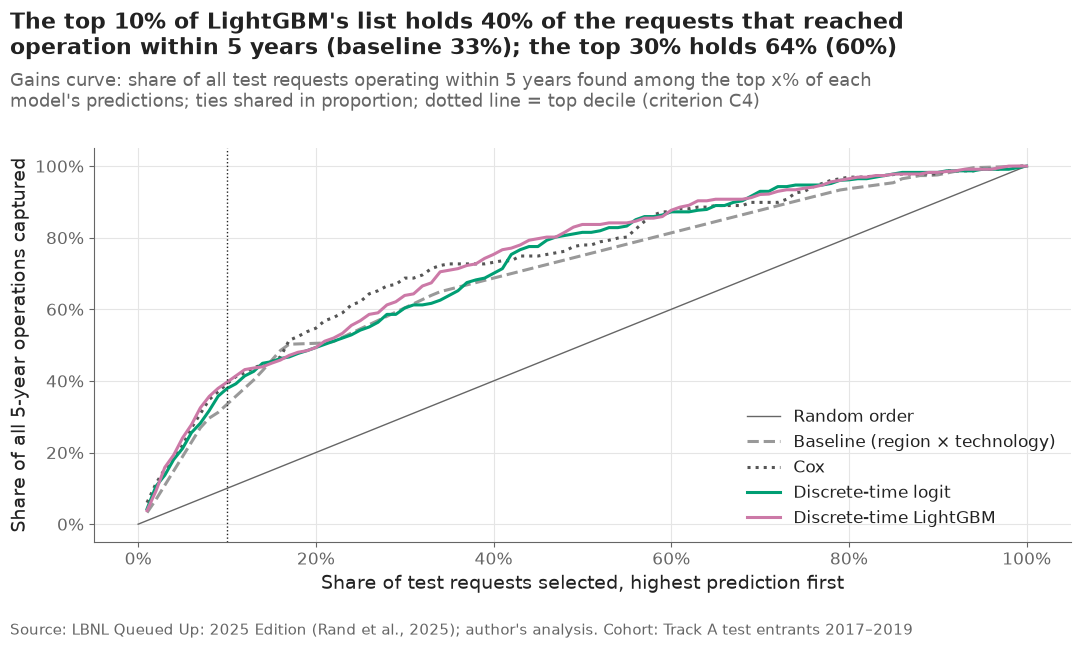

,top 10%,top 30%
model,,
baseline,0.335,0.604
cox,0.392,0.687
dt_logit,0.379,0.604
dt_lgbm,0.396,0.639


In [13]:
fractions = np.round(np.arange(0.01, 1.0001, 0.01), 2)
gain_rows = []
for h in HORIZONS:
    y_h, w_h = evaluation.horizon_outcome(durations, events, h, G)
    for model in MODELS:
        for f in fractions:
            top = evaluation.top_fraction(preds[h][model], y_h, w_h, f)
            gain_rows.append({"horizon": h, "model": model, "fraction": f, "captured": top["lift"] * f,
                              "precision": top["precision"]})
gains = pd.DataFrame(gain_rows)
gains.to_csv(paths.RESULTS / "gains.csv", index=False)

fig, ax = plt.subplots()
g5 = gains[gains["horizon"] == 5]
ax.plot([0, 1], [0, 1], color=plots.MUTED, linewidth=1, label="Random order")
for model in MODELS:
    part = g5[g5["model"] == model]
    style = {k: v for k, v in MODEL_STYLE[model].items() if k != "marker"}
    ax.plot(part["fraction"], part["captured"], label=MODEL_LABELS[model], **style)
ax.axvline(0.1, color=plots.INK, linewidth=1, linestyle=":")
ax.set_xlabel("Share of test requests selected, highest prediction first")
ax.set_ylabel("Share of all 5-year operations captured")
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.legend(loc="lower right")
cap = g5[g5["fraction"] == 0.1].set_index("model")["captured"]
cap30 = g5[g5["fraction"] == 0.3].set_index("model")["captured"]
plots.finish(fig,
             f"The top 10% of LightGBM's list holds {cap['dt_lgbm']:.0%} of the requests that reached operation within 5 "
             f"years (baseline {cap['baseline']:.0%}); the top 30% holds {cap30['dt_lgbm']:.0%} ({cap30['baseline']:.0%})",
             "Gains curve: share of all test requests operating within 5 years found among the top x% of each model's "
             "predictions; ties shared in proportion; dotted line = top decile (criterion C4)",
             "Track A test entrants 2017–2019")
save(fig, "08_08_gains_5yr", "Gains curves at 5 years: share of operating requests captured by the top x% of each model's ranking.")
plt.show()
pd.DataFrame({"top 10%": cap, "top 30%": cap30}).loc[MODELS].round(3)

**Reading this.** If a lender could examine only the top 10% of LightGBM's 5-year list, it would find 39.6% of all requests that reached operation within 5 years; ordering by the baseline finds 33.5%, Cox 39.2%. At the top 30% the shares are 63.9% (LightGBM), 60.4% (baseline) and 68.7% (Cox). The curves separate mostly at the very top of the list, where screening decisions are made; beyond about 40% of the list all models capture nearly the same operations.

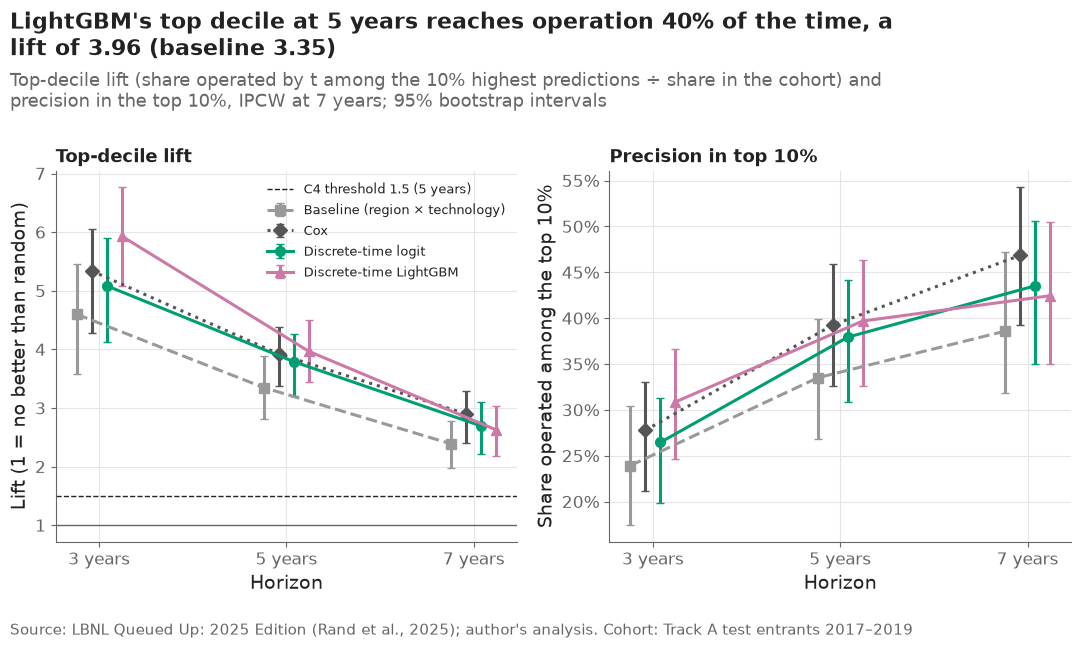

model                             baseline                   cox              dt_logit               dt_lgbm
metric       horizon                                                                                        
lift_10      3        4.599 [3.588, 5.462]  5.339 [4.285, 6.049]  5.085 [4.128, 5.893]  5.932 [5.078, 6.763]
             5        3.347 [2.806, 3.880]  3.921 [3.378, 4.375]  3.789 [3.201, 4.256]  3.965 [3.440, 4.507]
             7        2.386 [1.972, 2.781]  2.897 [2.397, 3.285]  2.692 [2.217, 3.103]  2.625 [2.179, 3.035]
precision_10 3        0.239 [0.174, 0.304]  0.278 [0.212, 0.331]  0.265 [0.198, 0.313]  0.309 [0.247, 0.366]
             5        0.335 [0.269, 0.399]  0.392 [0.326, 0.459]  0.379 [0.309, 0.441]  0.397 [0.326, 0.463]
             7        0.386 [0.318, 0.472]  0.468 [0.393, 0.543]  0.435 [0.350, 0.506]  0.424 [0.350, 0.505]

In [14]:
fig, axes = plt.subplots(1, 2, sharex=True)
for ax, metric in zip(axes, ["lift_10", "precision_10"]):
    if metric == "lift_10":
        ax.axhline(1.5, color=plots.INK, linewidth=1, linestyle="--", label="C4 threshold 1.5 (5 years)")
        ax.axhline(1.0, color=plots.MUTED, linewidth=1)
    for model in MODELS:
        part = metrics_a[(metrics_a["model"] == model) & (metrics_a["metric"] == metric)]
        errorbars(ax, part["horizon"] + OFFSETS[model], part, label=MODEL_LABELS[model], **MODEL_STYLE[model])
    ax.set_xticks(HORIZONS, [f"{h} years" for h in HORIZONS])
    ax.set_xlabel("Horizon")
    ax.set_title(METRIC_LABELS[metric], fontsize=13)
axes[1].yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[0].set_ylabel("Lift (1 = no better than random)")
axes[1].set_ylabel("Share operated among the top 10%")
axes[0].legend(loc="upper right", fontsize=9.5)
plots.finish(fig,
             f"LightGBM's top decile at 5 years reaches operation {value(metrics_a, 'dt_lgbm', 'precision_10', 5):.0%} of the "
             f"time, a lift of {value(metrics_a, 'dt_lgbm', 'lift_10', 5):.2f} (baseline "
             f"{value(metrics_a, 'baseline', 'lift_10', 5):.2f})",
             "Top-decile lift (share operated by t among the 10% highest predictions ÷ share in the cohort) and precision "
             "in the top 10%, IPCW at 7 years; 95% bootstrap intervals",
             "Track A test entrants 2017–2019")
save(fig, "08_09_top_decile", "Top-decile lift and precision of the four Track A models by horizon.")
plt.show()
lift = metrics_a[metrics_a["metric"].isin(["lift_10", "precision_10"])].copy()
lift["value"] = [f"{r.estimate:.3f} [{r.low:.3f}, {r.high:.3f}]" for r in lift.itertuples()]
lift.pivot_table(index=["metric", "horizon"], columns="model", values="value", aggfunc="first")[MODELS]

**Reading this.** LightGBM's top decile reaches operation within 5 years 39.7% [32.6%, 46.3%] of the time, against 227 of 2,268 (10.0%) in the whole cohort, a lift of 3.96 [3.44, 4.51]; criterion C4 (lift ≥ 1.5) passes with room. The baseline's lift is 3.35 [2.81, 3.88], because region alone already concentrates operations in ERCOT and PJM's gas and small requests. At 3 years LightGBM's lift is 5.93 [5.08, 6.76] against 4.60 for the baseline. The precision in the top decile — about 2 in 5 at 5 years — is the number a developer can use directly.

## 5. Track B: will a 2017 request ever be built? (all nine regions)

The 2017 cohort's resolved requests, scored for the first time: the
region × technology base rate, the logit and LightGBM as fitted on entrants
to 2015, and both after the isotonic map fitted on 2016 (decision #29).
Criterion C5 compares the calibrated LightGBM with the base rate. Track B
keeps only resolved requests (notebook 04), so the 2017 cohort is tilted
towards fast outcomes; the share of each region's 2017 requests still
unresolved is shown beside the per-region results.

In [15]:
pred_b = pd.read_parquet(paths.DATA_PROCESSED / "predictions_trackB.parquet")
test_b = pred_b[pred_b["split"] == "test"].reset_index(drop=True)
y_b = test_b["built"].to_numpy()
B_MODELS = ["baseline", "logit", "lgbm", "logit_cal", "lgbm_cal"]
B_LABELS = {"baseline": "Base rate (region × technology)", "logit": "Logit", "lgbm": "LightGBM",
            "logit_cal": "Logit, calibrated", "lgbm_cal": "LightGBM, calibrated"}
B_STYLE = {"baseline": dict(color="#999999", marker="s"), "logit": dict(color="#009E73", marker="o", markerfacecolor="white"),
           "lgbm": dict(color="#CC79A7", marker="^", markerfacecolor="white"), "logit_cal": dict(color="#009E73", marker="o"),
           "lgbm_cal": dict(color="#CC79A7", marker="^")}
preds_b = {m: test_b[m].to_numpy() for m in B_MODELS}
point_b = evaluation.score(preds_b, y_b)
draws_b = evaluation.bootstrap(lambda sw: evaluation.score(preds_b, y_b, None, sw), len(test_b), N_BOOT,
                               REGISTERED["seed_track_b"])
metrics_b = evaluation.summarise(point_b, draws_b, level=LEVEL)
metrics_b.insert(0, "track", "B")
metrics_b.insert(3, "horizon", np.nan)
print(f"2017 cohort: {len(test_b):,} resolved requests, {y_b.sum():,} built ({y_b.mean():.1%}); "
      f"mean prediction: " + ", ".join(f"{m} {preds_b[m].mean():.1%}" for m in B_MODELS))
mb = metrics_b.copy()
mb["value"] = [f"{r.estimate:.3f} [{r.low:.3f}, {r.high:.3f}]" for r in mb.itertuples()]
mb["vs base rate"] = [f"{r.diff:+.3f} [{r.diff_low:+.3f}, {r.diff_high:+.3f}]" if pd.notna(r.diff) else "" for r in mb.itertuples()]
mb.pivot_table(index="model", columns="metric", values="value", aggfunc="first").loc[B_MODELS, ["auc", "brier", "slope", "intercept", "lift_10"]]

2017 cohort: 1,534 resolved requests, 279 built (18.2%); mean prediction: baseline 18.4%, logit 20.6%, lgbm 20.6%, logit_cal 17.9%, lgbm_cal 19.0%


metric,auc,brier,slope,intercept,lift_10
model,,,,,
baseline,"0.525 [0.478, 0.564]","0.153 [0.141, 0.166]","0.119 [-0.106, 0.327]","-0.016 [-0.122, 0.123]","1.788 [1.397, 2.142]"
logit,"0.598 [0.557, 0.629]","0.157 [0.146, 0.170]","0.388 [0.236, 0.520]","-0.176 [-0.299, -0.034]","1.484 [1.106, 1.890]"
lgbm,"0.612 [0.576, 0.648]","0.148 [0.138, 0.160]","0.658 [0.464, 0.864]","-0.166 [-0.281, -0.034]","1.541 [1.216, 1.940]"
logit_cal,"0.603 [0.563, 0.634]","0.148 [0.136, 0.160]","0.597 [0.421, 0.749]","0.018 [-0.095, 0.153]","1.508 [1.103, 1.842]"
lgbm_cal,"0.608 [0.574, 0.640]","0.147 [0.137, 0.160]","0.600 [0.402, 0.816]","-0.060 [-0.177, 0.070]","1.619 [1.303, 1.943]"


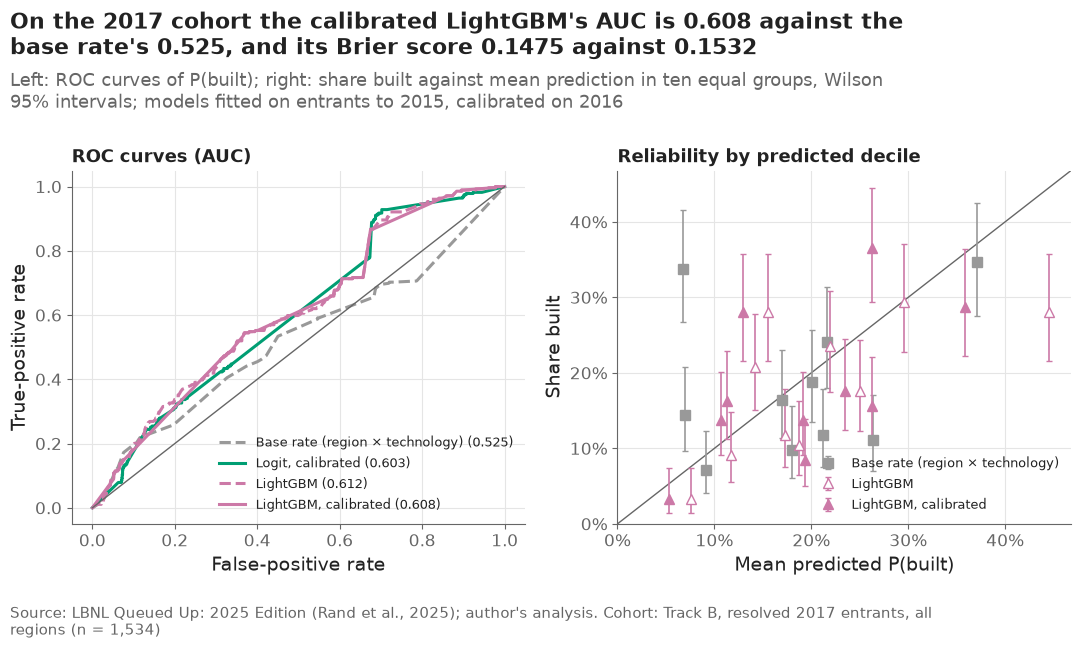

In [16]:
fig, axes = plt.subplots(1, 2)
for model in ["baseline", "logit_cal", "lgbm", "lgbm_cal"]:
    fpr, tpr, _ = roc_curve(y_b, preds_b[model])
    style = {k: v for k, v in B_STYLE[model].items() if k not in ("marker", "markerfacecolor")}
    axes[0].plot(fpr, tpr, linestyle="--" if model in ("baseline", "lgbm") else "-",
                 label=f"{B_LABELS[model]} ({point_b[model + '|auc']:.3f})", **style)
axes[0].plot([0, 1], [0, 1], color=plots.MUTED, linewidth=1)
axes[0].set_xlabel("False-positive rate")
axes[0].set_ylabel("True-positive rate")
axes[0].set_title("ROC curves (AUC)", fontsize=13)
axes[0].legend(loc="lower right", fontsize=9.5)
rel_rows = []
for model in ["baseline", "lgbm", "lgbm_cal"]:
    groups = evaluation.decile_groups(preds_b[model])
    for g in range(10):
        idx = groups == g
        low, high = track_b.wilson(y_b[idx].sum(), idx.sum())
        rel_rows.append({"model": model, "decile": g + 1, "predicted": preds_b[model][idx].mean(),
                         "observed": y_b[idx].mean(), "low": low, "high": high})
reliability_b = pd.DataFrame(rel_rows)
top = reliability_b[["high", "predicted"]].max().max() * 1.05
axes[1].plot([0, top], [0, top], color=plots.MUTED, linewidth=1)
for model in ["baseline", "lgbm", "lgbm_cal"]:
    part = reliability_b[reliability_b["model"] == model]
    axes[1].errorbar(part["predicted"], part["observed"], yerr=[part["observed"] - part["low"], part["high"] - part["observed"]],
                     fmt=B_STYLE[model]["marker"], color=B_STYLE[model]["color"],
                     markerfacecolor=B_STYLE[model].get("markerfacecolor", B_STYLE[model]["color"]), capsize=2,
                     linewidth=1.2, label=B_LABELS[model])
axes[1].set_xlim(0, top)
axes[1].set_ylim(0, top)
axes[1].set_xlabel("Mean predicted P(built)")
axes[1].set_ylabel("Share built")
axes[1].set_title("Reliability by predicted decile", fontsize=13)
axes[1].xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
axes[1].yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[1].legend(loc="lower right", fontsize=9.5)
plots.finish(fig,
             f"On the 2017 cohort the calibrated LightGBM's AUC is {point_b['lgbm_cal|auc']:.3f} against the base rate's "
             f"{point_b['baseline|auc']:.3f}, and its Brier score {point_b['lgbm_cal|brier']:.4f} against "
             f"{point_b['baseline|brier']:.4f}",
             "Left: ROC curves of P(built); right: share built against mean prediction in ten equal groups, Wilson 95% "
             "intervals; models fitted on entrants to 2015, calibrated on 2016",
             f"Track B, resolved 2017 entrants, all regions (n = {len(test_b):,})")
save(fig, "08_10_trackB_roc_reliability", "Track B on the 2017 cohort: ROC curves and reliability by predicted decile.")
plt.show()

**Reading this.** On the 2017 cohort (1,534 resolved requests across nine regions, 279 built, 18.2%), the calibrated LightGBM's AUC is 0.608 [0.574, 0.640] against 0.525 [0.478, 0.564] for the region × technology base rate — a paired gain of +0.084 [+0.050, +0.119] — and its Brier score 0.1475 against 0.1532, lower by 0.0057 [0.0024, 0.0093]. Criterion C5 passes on both. The win comes partly from the base rate collapsing: its AUC was 0.613 on the 2016 cohort (notebook 07) and 0.525 here, close to random, so the historical region × technology mix no longer ranks 2017 requests. In absolute terms Track B remains weak (AUC about 0.61), and the calibrated model's slope of 0.600 [0.402, 0.816] says its probabilities are too spread out: treat Track B as a coarse ranking outside the three ISOs, not as a probability.

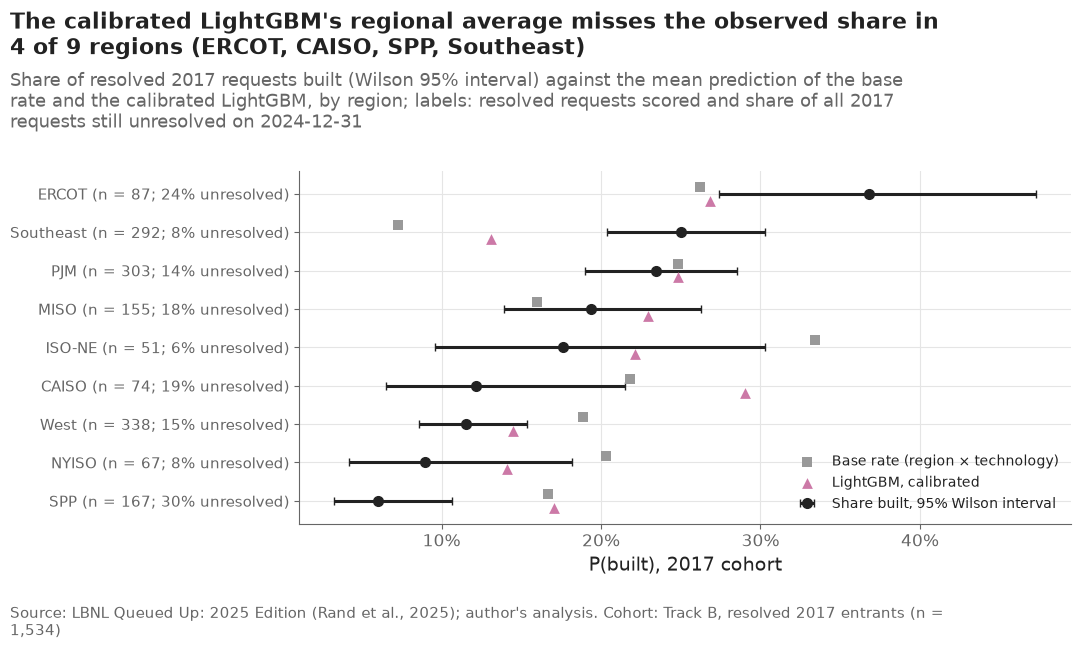

,region,n,built,low,high,unresolved_2017_share,baseline,logit,lgbm,logit_cal,lgbm_cal,lgbm_cal_inside
0,ERCOT,87,0.368,0.274,0.473,0.243,0.262,0.262,0.304,0.220,0.269,False
1,PJM,303,0.234,0.190,0.285,0.142,0.248,0.318,0.260,0.264,0.249,True
2,CAISO,74,0.122,0.065,0.215,0.187,0.218,0.270,0.308,0.224,0.291,False
3,MISO,155,0.194,0.139,0.263,0.180,0.160,0.200,0.229,0.179,0.230,True
4,SPP,167,0.060,0.033,0.107,0.304,0.167,0.132,0.176,0.120,0.171,False
5,NYISO,67,0.090,0.042,0.182,0.082,0.203,0.174,0.158,0.172,0.141,True
6,ISO-NE,51,0.176,0.096,0.303,0.056,0.334,0.252,0.229,0.212,0.221,True
7,West,338,0.115,0.086,0.154,0.149,0.189,0.176,0.160,0.147,0.145,True
8,Southeast,292,0.250,0.204,0.303,0.085,0.072,0.136,0.160,0.136,0.131,False


In [17]:
events_all = pd.read_parquet(paths.DATA_INTERIM / "queue_events.parquet")
cohort17 = events_all[events_all["q_year"].astype(float) == config.TRACK_B_MAX_YEAR]
unresolved = 1 - cohort17["q_status"].isin(["operational", "withdrawn"]).groupby(cohort17["region"]).mean()
by_region_rows = []
for region in config.ALL_REGIONS:
    part = test_b[test_b["region"] == region]
    low, high = track_b.wilson(part["built"].sum(), len(part))
    by_region_rows.append({"region": region, "n": len(part), "built": part["built"].mean(), "low": low, "high": high,
                           "unresolved_2017_share": unresolved.get(region, np.nan),
                           **{m: part[m].mean() for m in B_MODELS}})
b_region = pd.DataFrame(by_region_rows)
b_region["lgbm_cal_inside"] = (b_region["lgbm_cal"] >= b_region["low"]) & (b_region["lgbm_cal"] <= b_region["high"])
b_region.to_csv(paths.RESULTS / "trackB_test_by_region.csv", index=False)

fig, ax = plt.subplots()
order = b_region.sort_values("built")["region"].tolist()
y = np.arange(len(order))
part = b_region.set_index("region").loc[order]
ax.errorbar(part["built"], y, xerr=[part["built"] - part["low"], part["high"] - part["built"]], fmt="o", color=plots.INK,
            capsize=3, label="Share built, 95% Wilson interval")
ax.scatter(part["baseline"], y + 0.18, marker="s", color=B_STYLE["baseline"]["color"], s=50, zorder=3,
           label=B_LABELS["baseline"])
ax.scatter(part["lgbm_cal"], y - 0.18, marker="^", color=B_STYLE["lgbm_cal"]["color"], s=60, zorder=3,
           label=B_LABELS["lgbm_cal"])
ax.set_yticks(y, [f"{r} (n = {int(part.loc[r, 'n'])}; {part.loc[r, 'unresolved_2017_share']:.0%} unresolved)" for r in order],
              fontsize=11)
ax.set_xlabel("P(built), 2017 cohort")
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.legend(loc="lower right", fontsize=10)
missed = b_region.loc[~b_region["lgbm_cal_inside"], "region"].tolist()
plots.finish(fig,
             f"The calibrated LightGBM's regional average misses the observed share in {len(missed)} of 9 regions"
             + (f" ({', '.join(missed)})" if missed else ""),
             "Share of resolved 2017 requests built (Wilson 95% interval) against the mean prediction of the base rate and "
             "the calibrated LightGBM, by region; labels: resolved requests scored and share of all 2017 requests "
             "still unresolved on 2024-12-31",
             f"Track B, resolved 2017 entrants (n = {len(test_b):,})")
save(fig, "08_11_trackB_by_region", "Track B on the 2017 cohort: observed share built versus mean predictions by region.")
plt.show()
b_region.round(3)

**Reading this.** The calibrated LightGBM's regional average misses the observed share in 4 of 9 regions: ERCOT (36.8% built [27.4%, 47.3%], 26.9% predicted), the Southeast (25.0% vs 13.1%), CAISO (12.2% vs 29.1%) and SPP (6.0% vs 17.1%). Two caveats: Track B scores resolved requests only, and the unresolved share of 2017 entrants differs by region — 30.4% in SPP, 24.3% in ERCOT, 8.5% in the Southeast — so a region's observed "share built" is the share among those that have finished; and the per-region intervals are wide (ISO-NE has 51 resolved requests).

## 6. The pre-registered criteria: PASS or FAIL

Each line of `results/success_criteria_registered.json` (written by the
first cell) is judged by its registered rule against the tables above. No
line is added, dropped or redefined here.

In [18]:
all_metrics = pd.concat([metrics_a, metrics_b], ignore_index=True)
all_metrics.to_csv(paths.RESULTS / "metrics.csv", index=False)
crit_rows = []
for c in REGISTERED["criteria"]:
    table = metrics_a if c["track"] == "A" else metrics_b
    for h in c["horizons"]:
        row = table[(table["model"] == c["model"]) & (table["metric"] == c["metric"])
                    & ((table["horizon"] == h) if h is not None else True)].iloc[0]
        entry = {"id": c["id"], "track": c["track"], "model": c["model"], "metric": c["metric"],
                 "horizon": h, "rule": c["rule"], "estimate": row["estimate"], "low": row["low"], "high": row["high"]}
        if c["rule"] == "beat":
            ref = table[(table["model"] == c["benchmark"]) & (table["metric"] == c["metric"])
                        & ((table["horizon"] == h) if h is not None else True)].iloc[0]
            entry.update({"benchmark": c["benchmark"], "benchmark_estimate": ref["estimate"], "diff": row["diff"],
                          "diff_low": row["diff_low"], "diff_high": row["diff_high"]})
            passed = bool(row["beats"])
            entry["threshold"] = "95% interval of the difference excludes 0 on the better side"
        elif c["rule"] == "between":
            passed = c["low"] <= row["estimate"] <= c["high"]
            entry["threshold"] = f"{c['low']}–{c['high']}"
        else:
            passed = row["estimate"] >= c["value"]
            entry["threshold"] = f"≥ {c['value']}"
        entry["result"] = "PASS" if passed else "FAIL"
        if c["rule"] == "beat":  # reported only: the registered rule is the interval (decision #5)
            better = row["diff"] > 0 if c["metric"] in ("uno_c", "auc") else row["diff"] < 0
            entry["point_estimate_reading"] = "better" if better else "not better"
        crit_rows.append(entry)
criteria = pd.DataFrame(crit_rows)
criteria.to_csv(paths.RESULTS / "success_criteria.csv", index=False)
print(f"{(criteria['result'] == 'PASS').sum()} of {len(criteria)} criterion lines pass")
print("lines the point estimate alone would call better although the registered interval rule says FAIL:",
      int(((criteria["point_estimate_reading"] == "better") & (criteria["result"] == "FAIL")).sum()))
criteria[["id", "track", "metric", "horizon", "estimate", "low", "high", "benchmark_estimate", "diff", "diff_low",
          "diff_high", "threshold", "result", "point_estimate_reading"]].round(4)

8 of 12 criterion lines pass
lines the point estimate alone would call better although the registered interval rule says FAIL: 2


,id,track,metric,horizon,estimate,low,high,benchmark_estimate,diff,diff_low,diff_high,threshold,result,point_estimate_reading
0,C1,A,uno_c,3.0,0.8525,0.8198,0.8858,0.7311,0.1215,0.0722,0.1699,95% interval of the difference excludes 0 on t...,PASS,better
1,C1,A,uno_c,5.0,0.7597,0.7315,0.7908,0.7191,0.0407,0.0128,0.0685,95% interval of the difference excludes 0 on t...,PASS,better
2,C1,A,uno_c,7.0,0.6722,0.6373,0.7003,0.6574,0.0148,-0.0142,0.0496,95% interval of the difference excludes 0 on t...,FAIL,better
3,C2,A,brier,3.0,0.0411,0.0353,0.0478,0.0471,-0.0059,-0.0082,-0.0039,95% interval of the difference excludes 0 on t...,PASS,better
4,C2,A,brier,5.0,0.0808,0.0736,0.0886,0.0858,-0.0050,-0.0074,-0.0028,95% interval of the difference excludes 0 on t...,PASS,better
5,C2,A,brier,7.0,0.1211,0.1125,0.1330,0.1219,-0.0008,-0.0041,0.0023,95% interval of the difference excludes 0 on t...,FAIL,better
6,C3,A,slope,3.0,1.3448,1.1511,1.5791,NaN,NaN,NaN,NaN,0.9–1.1,FAIL,NaN
7,C3,A,slope,5.0,1.2728,1.1096,1.4891,NaN,NaN,NaN,NaN,0.9–1.1,FAIL,NaN
8,C3,A,slope,7.0,0.9395,0.7222,1.1359,NaN,NaN,NaN,NaN,0.9–1.1,PASS,NaN
9,C4,A,lift_10,5.0,3.9648,3.4401,4.5072,NaN,NaN,NaN,NaN,≥ 1.5,PASS,NaN


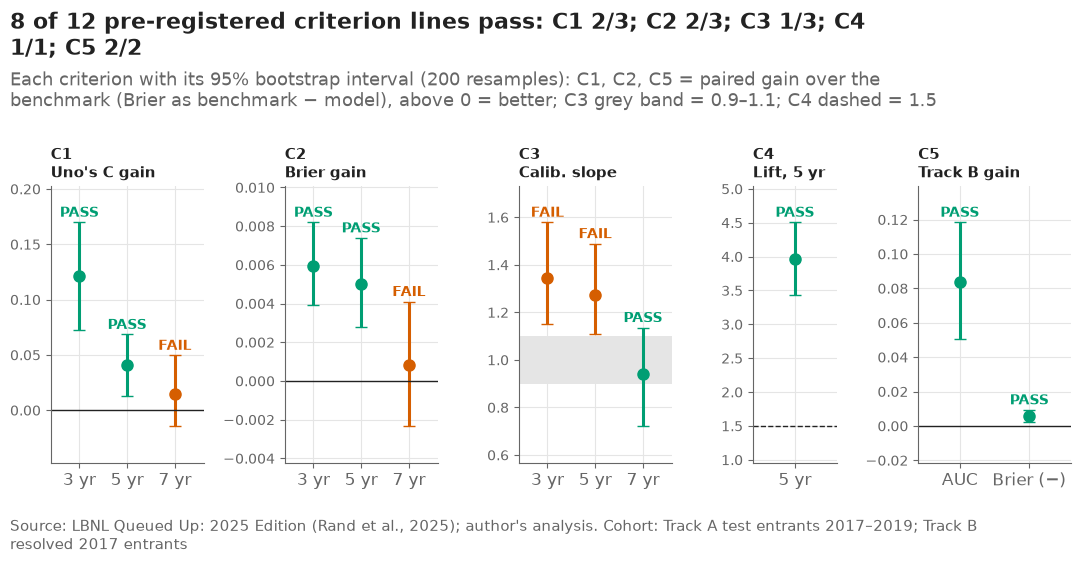

In [19]:
fig, axes = plt.subplots(1, 5, figsize=(11, 5.6), gridspec_kw={"width_ratios": [1, 1, 1, 0.55, 1]})
panels = [("C1", "uno_c", "Uno's C gain", 0.0), ("C2", "brier", "Brier gain", 0.0),
          ("C3", "slope", "Calib. slope", None), ("C4", "lift_10", "Lift, 5 yr", 1.5),
          ("C5", None, "Track B gain", 0.0)]
for ax, (cid, metric, title, ref) in zip(axes, panels):
    part = criteria[(criteria["id"] == cid) & ((criteria["metric"] == metric) if metric else True)]
    for i, row in enumerate(part.itertuples()):
        use_diff = row.rule == "beat"
        est, low, high = (row.diff, row.diff_low, row.diff_high) if use_diff else (row.estimate, row.low, row.high)
        if row.metric == "brier":
            est, low, high = -est, -high, -low  # Brier gains drawn as benchmark − model, so above 0 is better everywhere
        color = "#009E73" if row.result == "PASS" else "#D55E00"
        ax.errorbar(i, est, yerr=[[est - low], [high - est]], fmt="o", color=color, capsize=4, markersize=8)
        ax.annotate(row.result, (i, high), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=10,
                    color=color, fontweight="bold")
    labels = [f"{int(h)} yr" if pd.notna(h) else ("AUC" if m == "auc" else "Brier (−)") for h, m in zip(part["horizon"], part["metric"])]
    ax.set_xticks(range(len(part)), labels)
    ax.set_xlim(-0.6, len(part) - 0.4)
    if cid == "C3":
        ax.axhspan(0.9, 1.1, color="#E5E5E5")
    elif ref is not None:
        ax.axhline(ref, color=plots.INK, linewidth=1, linestyle="--" if cid == "C4" else "-")
    ax.set_title(f"{cid}\n{title}", fontsize=11)
    ax.tick_params(axis="y", labelsize=10)
    ax.margins(y=0.18)
n_pass = int((criteria["result"] == "PASS").sum())
plots.finish(fig,
             f"{n_pass} of {len(criteria)} pre-registered criterion lines pass: "
             + "; ".join(f"{cid} {int((criteria.loc[criteria['id'] == cid, 'result'] == 'PASS').sum())}/"
                         f"{int((criteria['id'] == cid).sum())}" for cid in ["C1", "C2", "C3", "C4", "C5"]),
             "Each criterion with its 95% bootstrap interval (200 resamples): C1, C2, C5 = paired gain over the benchmark "
             "(Brier as benchmark − model), above 0 = better; C3 grey band = 0.9–1.1; C4 dashed = 1.5",
             "Track A test entrants 2017–2019; Track B resolved 2017 entrants")
save(fig, "08_12_success_criteria", "The pre-registered success criteria with their bootstrap intervals and PASS/FAIL verdicts.")
plt.show()

**Reading this.** 8 of the 12 pre-registered criterion lines pass. C1 and C2 (beat the baseline on Uno's C and Brier) pass at 3 and 5 years and fail at 7 years, where the intervals include zero; C3 (calibration slope 0.9–1.1) fails at 3 and 5 years (1.34, 1.27) and passes at 7 (0.94); C4 (top-decile lift ≥ 1.5 at 5 years) passes at 3.96; C5 (Track B beats the base rate on AUC and Brier) passes on both. The point estimates at 7 years favour LightGBM (Uno +0.015, Brier −0.0008); read on point estimates alone those two lines would look like wins, which is why the rule was fixed in advance as an interval (decision #5): the 7-year gain is not distinguishable from noise. Read together: the model ranks requests better than cohort averages over a 3–5-year horizon and concentrates future operations in its top decile, but its mid-range probabilities are too high and its 7-year advantage is unproven.

## 7. The 7-year horizon and the three entry years

Two checks on what the pooled numbers hide. First, the 7-year metrics
recomputed on 2017 entrants alone, whose 7-year status is fully observed (no
weights), against the IPCW numbers on all test entrants. Second, the mean
prediction against the observed incidence for each entry year: the models
were fitted on entrants to 2016, and 2019 is further from that than 2017.

2017 entrants: 549; operated within 7 years: 99


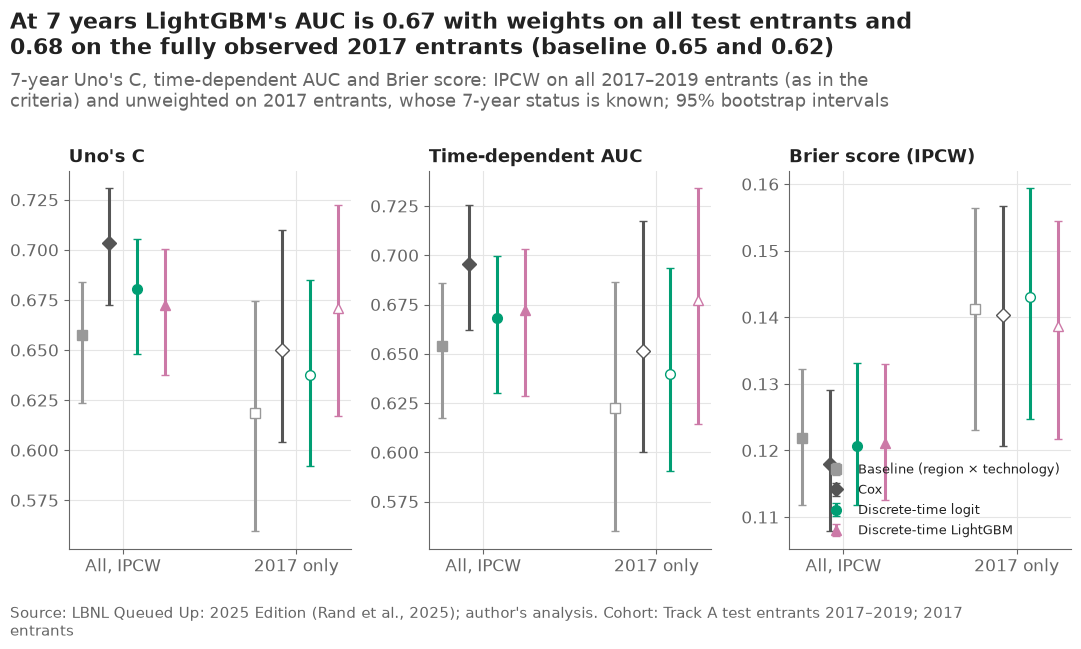

model                                             baseline                   cox              dt_logit               dt_lgbm
metric version                                                                                                              
auc    2017 entrants, fully observed  0.623 [0.560, 0.686]  0.651 [0.600, 0.717]  0.640 [0.590, 0.694]  0.677 [0.614, 0.734]
       2017–2019 entrants, IPCW       0.654 [0.617, 0.686]  0.696 [0.662, 0.726]  0.668 [0.630, 0.700]  0.672 [0.629, 0.703]
brier  2017 entrants, fully observed  0.141 [0.123, 0.156]  0.140 [0.121, 0.157]  0.143 [0.125, 0.159]  0.139 [0.122, 0.155]
       2017–2019 entrants, IPCW       0.122 [0.112, 0.132]  0.118 [0.108, 0.129]  0.121 [0.112, 0.133]  0.121 [0.113, 0.133]
slope  2017 entrants, fully observed  0.938 [0.503, 1.494]  1.053 [0.683, 1.503]  0.695 [0.452, 0.976]  0.897 [0.589, 1.240]
       2017–2019 entrants, IPCW       1.076 [0.772, 1.364]  1.322 [1.074, 1.548]  0.787 [0.614, 0.931]  0.939 [0.722, 1.136]
uno_c  2017 entrants, fully observed  0.619 [0.560, 0.674]  0.650 [0.604, 0.710]  0.638 [0.592, 0.685]  0.671 [0.617, 0.723]
       2017–2019 entrants, IPCW       0.657 [0.623, 0.684]  0.703 [0.672, 0.731]  0.681 [0.648, 0.706]  0.672 [0.637, 0.700]

In [20]:
in_2017 = test["q_year"].to_numpy() == 2017
assert (follow_up[in_2017] > 7).all()
G_2017 = evaluation.censoring_km(follow_up[in_2017], np.ones(in_2017.sum(), dtype=bool))
sub = {m: preds[7][m][in_2017] for m in MODELS}
point = evaluation.score_horizon(sub, durations[in_2017], events[in_2017], 7, G_2017)
draws = evaluation.bootstrap(lambda sw: evaluation.score_horizon(sub, durations[in_2017], events[in_2017], 7, G_2017, sw),
                             int(in_2017.sum()), N_BOOT, REGISTERED["seed_track_a"] + 20)
seven = pd.concat([evaluation.summarise(point, draws, level=LEVEL).assign(version="2017 entrants, fully observed"),
                   metrics_a[metrics_a["horizon"] == 7].drop(columns=["track", "horizon"]).assign(version="2017–2019 entrants, IPCW")],
                  ignore_index=True)
seven.to_csv(paths.RESULTS / "seven_year_check.csv", index=False)
print(f"2017 entrants: {in_2017.sum():,}; operated within 7 years: {int(((events == 1) & (durations <= 7) & in_2017).sum())}")

fig, axes = plt.subplots(1, 3)
for ax, metric in zip(axes, ["uno_c", "auc", "brier"]):
    for v_i, (version, face) in enumerate([("2017–2019 entrants, IPCW", None), ("2017 entrants, fully observed", "white")]):
        for model in MODELS:
            row = seven[(seven["version"] == version) & (seven["model"] == model) & (seven["metric"] == metric)]
            style = MODEL_STYLE[model]
            ax.errorbar(v_i + OFFSETS[model], row["estimate"], yerr=[row["estimate"] - row["low"], row["high"] - row["estimate"]],
                        fmt=style["marker"], color=style["color"], markerfacecolor=face or style["color"], capsize=3,
                        markersize=7, label=MODEL_LABELS[model] if v_i == 0 else None)
    ax.set_xticks([0, 1], ["All, IPCW", "2017 only"])
    ax.set_title(METRIC_LABELS[metric], fontsize=13)
axes[2].legend(loc="lower right", fontsize=9)
s7 = seven.set_index(["version", "model", "metric"])["estimate"]
plots.finish(fig,
             f"At 7 years LightGBM's AUC is {s7[('2017–2019 entrants, IPCW', 'dt_lgbm', 'auc')]:.2f} with weights on all "
             f"test entrants and {s7[('2017 entrants, fully observed', 'dt_lgbm', 'auc')]:.2f} on the fully observed 2017 "
             f"entrants (baseline {s7[('2017–2019 entrants, IPCW', 'baseline', 'auc')]:.2f} and "
             f"{s7[('2017 entrants, fully observed', 'baseline', 'auc')]:.2f})",
             "7-year Uno's C, time-dependent AUC and Brier score: IPCW on all 2017–2019 entrants (as in the criteria) "
             "and unweighted on 2017 entrants, whose 7-year status is known; 95% bootstrap intervals",
             "Track A test entrants 2017–2019; 2017 entrants")
save(fig, "08_13_seven_year_check", "Seven-year metrics: IPCW on all test entrants versus the fully observed 2017 entrants.")
plt.show()
sv = seven[seven["metric"].isin(["uno_c", "auc", "brier", "slope"])].copy()
sv["value"] = [f"{r.estimate:.3f} [{r.low:.3f}, {r.high:.3f}]" for r in sv.itertuples()]
sv.pivot_table(index=["metric", "version"], columns="model", values="value", aggfunc="first")[MODELS]

**Reading this.** On the 549 fully observed 2017 entrants (99 operated within 7 years), LightGBM's 7-year AUC is 0.677 [0.614, 0.734] against the baseline's 0.623 [0.560, 0.686], Uno's C 0.671 against 0.619 and Brier 0.139 against 0.141; Cox is 0.651. The IPCW numbers on all test entrants (AUC 0.672 vs 0.654) tell the same story with a smaller gap. Both versions have wide, overlapping intervals: the 7-year comparison rests on one entry year and about a hundred operations, and neither version settles it.

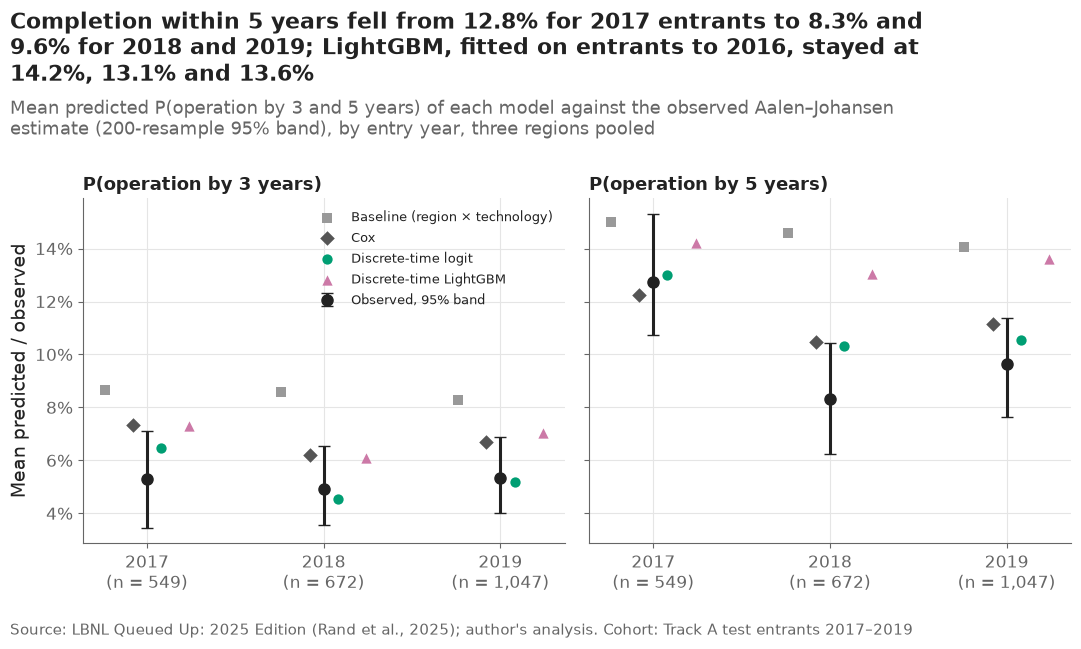

,entry_year,n,horizon,observed,low,high,baseline,cox,dt_logit,dt_lgbm
0,2017,549,3,0.053,0.035,0.071,0.087,0.073,0.065,0.073
1,2017,549,5,0.128,0.107,0.153,0.150,0.123,0.130,0.142
2,2018,672,3,0.049,0.036,0.065,0.086,0.062,0.046,0.061
3,2018,672,5,0.083,0.062,0.104,0.146,0.105,0.103,0.131
4,2019,1047,3,0.053,0.040,0.069,0.083,0.067,0.052,0.070
5,2019,1047,5,0.096,0.076,0.114,0.141,0.111,0.105,0.136


In [21]:
coh_rows = []
for y_i, year in enumerate([2017, 2018, 2019]):
    mask = test["q_year"].to_numpy() == year
    observed = survival_tools.aalen_johansen(durations[mask], events[mask], [3, 5])
    band = survival_tools.bootstrap_bands(durations[mask], events[mask], [3, 5], n_boot=N_BOOT, seed=830 + y_i)
    for j, h in enumerate([3, 5]):
        coh_rows.append({"entry_year": year, "n": int(mask.sum()), "horizon": h, "observed": observed["cif_operation"].iloc[j],
                         "low": band["cif_operation_low"].iloc[j], "high": band["cif_operation_high"].iloc[j],
                         **{m: preds[h][m][mask].mean() for m in MODELS}})
cohort_check = pd.DataFrame(coh_rows)
cohort_check.to_csv(paths.RESULTS / "cohort_check.csv", index=False)

fig, axes = plt.subplots(1, 2, sharey=True)
for ax, h in zip(axes, [3, 5]):
    part = cohort_check[cohort_check["horizon"] == h]
    x = np.arange(len(part))
    ax.errorbar(x, part["observed"], yerr=[part["observed"] - part["low"], part["high"] - part["observed"]], fmt="o",
                color=plots.INK, capsize=4, markersize=8, label="Observed, 95% band")
    for model in MODELS:
        ax.scatter(x + OFFSETS[model], part[model], marker=MODEL_STYLE[model]["marker"], color=MODEL_STYLE[model]["color"],
                   s=55, zorder=3, label=MODEL_LABELS[model])
    ax.set_xticks(x, [f"{y}\n(n = {n:,})" for y, n in zip(part["entry_year"], part["n"])])
    ax.set_title(f"P(operation by {h} years)", fontsize=13)
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[0].set_ylabel("Mean predicted / observed")
axes[0].legend(loc="upper right", fontsize=9.5)
cc = cohort_check.set_index(["entry_year", "horizon"])
plots.finish(fig,
             f"Completion within 5 years fell from {cc.loc[(2017, 5), 'observed']:.1%} for 2017 entrants to "
             f"{cc.loc[(2018, 5), 'observed']:.1%} and {cc.loc[(2019, 5), 'observed']:.1%} for 2018 and 2019; LightGBM, fitted on "
             f"entrants to 2016, stayed at {cc.loc[(2017, 5), 'dt_lgbm']:.1%}, {cc.loc[(2018, 5), 'dt_lgbm']:.1%} and "
             f"{cc.loc[(2019, 5), 'dt_lgbm']:.1%}",
             "Mean predicted P(operation by 3 and 5 years) of each model against the observed Aalen–Johansen estimate "
             "(200-resample 95% band), by entry year, three regions pooled",
             "Track A test entrants 2017–2019")
save(fig, "08_14_by_entry_year", "Mean predicted versus observed P(operation by 3 and 5 years) for each test entry year.")
plt.show()
cohort_check.round(3)

**Reading this.** Completion within 5 years fell from 12.8% [10.7%, 15.3%] for 2017 entrants to 8.3% [6.2%, 10.4%] for 2018 and 9.6% [7.7%, 11.4%] for 2019 entrants. LightGBM, fitted on entrants to 2016, predicted 14.2%, 13.1% and 13.6% — above the band for 2018 and 2019 — and the baseline 15.0%, 14.6% and 14.1%. The logit (13.0%, 10.3%, 10.5%) and Cox (12.3%, 10.5%, 11.1%) followed the fall more closely, plausibly because their request-year term extrapolates the downward trend while trees cannot extrapolate beyond the years they saw. This drift — not a coding error — is the main reason for LightGBM's high intercept, and it is a limitation for any user: a model trained on the past will over-predict while queues are slowing down.

## 8. Leave-one-ISO-out

Could the timing model be used in a region it has never seen? For each of
the three ISOs, both discrete-time models are refitted on the other two
ISOs' entrants to 2016 with region withheld (`pool_regions`; congestion is
still counted in each request's own queue) and notebook 06's settings, then
scored on the held-out ISO's 2017–2019 entrants. The benchmark for a region
nobody has seen is the technology-only Aalen–Johansen curve of the two
training ISOs. The main model, which did see the region, is shown for
reference.

In [22]:
clean = pd.read_parquet(paths.DATA_INTERIM / "queue_clean.parquet")
tuning = json.loads((paths.RESULTS / "dt_tuning.json").read_text(encoding="utf-8"))
final = track_a[track_a["q_year"] <= config.TRAIN_MAX_YEAR].copy()
loio_tables, loio_level = [], []
for r_i, held in enumerate(TRACK_A):
    train_r = final[final["region"] != held]
    mask = regions == held
    target = test[mask]
    fitted = discrete_time.fit_both(train_r, clean, tuning, pool_regions=True)
    p_r = discrete_time.predict_both(fitted, target)
    tech_only = survival_tools.baseline_cif(train_r.assign(region="pooled"), target.assign(region="pooled"), HORIZONS)
    G_r = evaluation.censoring_km(follow_up[mask], np.ones(mask.sum(), dtype=bool))
    observed = survival_tools.aalen_johansen(durations[mask], events[mask], HORIZONS)["cif_operation"].to_numpy()
    for j, h in enumerate(HORIZONS):
        sub = {"tech_baseline": tech_only[h].to_numpy(), "loio_logit": p_r["dt_logit"][h].to_numpy(),
               "loio_lgbm": p_r["dt_lgbm"][h].to_numpy(), "main_lgbm": preds[h]["dt_lgbm"][mask]}
        point = evaluation.score_horizon(sub, durations[mask], events[mask], h, G_r)
        draws = evaluation.bootstrap(lambda sw: evaluation.score_horizon(sub, durations[mask], events[mask], h, G_r, sw),
                                     int(mask.sum()), N_BOOT, REGISTERED["seed_track_a"] + 30 + r_i)
        table = evaluation.summarise(point, draws, reference="tech_baseline", level=LEVEL)
        table.insert(0, "held_out", held)
        table.insert(3, "horizon", h)
        loio_tables.append(table)
        loio_level.append({"held_out": held, "horizon": h, "observed": observed[j], **{k: v.mean() for k, v in sub.items()}})
loio = pd.concat(loio_tables, ignore_index=True)
loio_level = pd.DataFrame(loio_level)
loio = loio.merge(loio_level.melt(id_vars=["held_out", "horizon", "observed"], var_name="model", value_name="mean_predicted"),
                  on=["held_out", "horizon", "model"], how="left")
loio.to_csv(paths.RESULTS / "loio.csv", index=False)
print(f"refits done at {(time.time() - START) / 60:.1f} minutes")
loio_level.round(3)

refits done at 1.6 minutes


,held_out,horizon,observed,tech_baseline,loio_logit,loio_lgbm,main_lgbm
0,ERCOT,3,0.054,0.078,0.014,0.015,0.080
1,ERCOT,5,0.167,0.132,0.033,0.025,0.176
2,ERCOT,7,0.215,0.176,0.046,0.031,0.250
3,PJM,3,0.059,0.027,0.015,0.049,0.077
4,PJM,5,0.094,0.072,0.026,0.156,0.145
5,PJM,7,0.167,0.117,0.036,0.284,0.204
6,CAISO,3,0.015,0.120,0.103,0.107,0.012
7,CAISO,5,0.031,0.180,0.193,0.239,0.036
8,CAISO,7,0.046,0.212,0.260,0.334,0.073


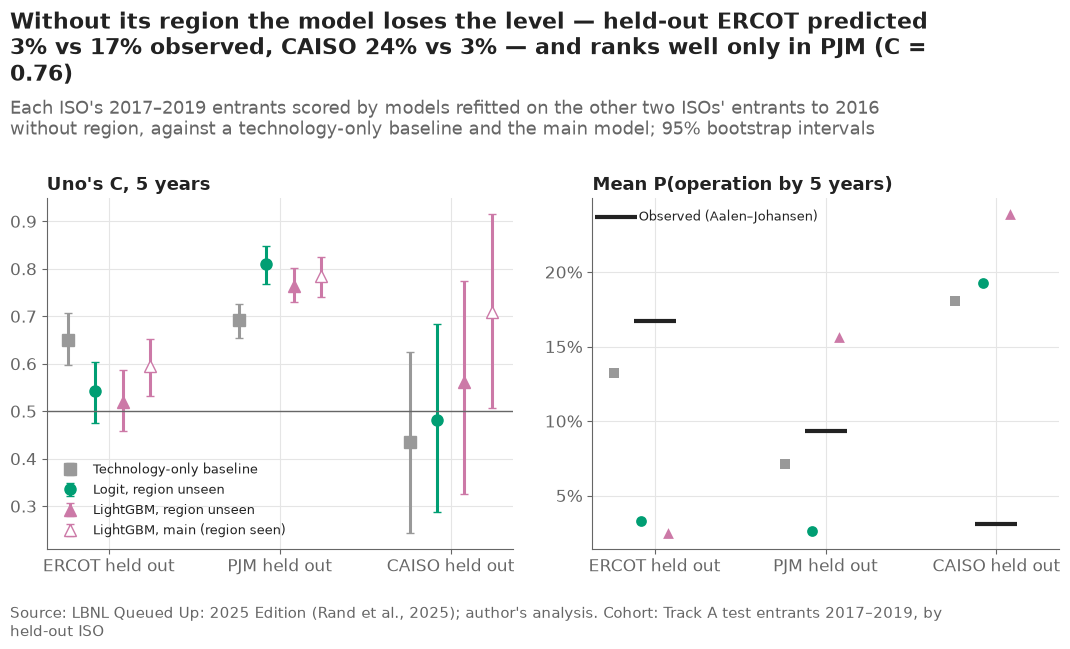

model                           tech_baseline            loio_logit             loio_lgbm             main_lgbm
held_out metric horizon                                                                                        
CAISO    auc    3        0.628 [0.354, 0.859]  0.740 [0.521, 0.885]  0.856 [0.633, 0.988]  0.970 [0.910, 1.000]
                5        0.431 [0.241, 0.623]  0.480 [0.286, 0.686]  0.561 [0.327, 0.777]  0.709 [0.507, 0.917]
                7        0.458 [0.282, 0.621]  0.480 [0.317, 0.653]  0.501 [0.342, 0.679]  0.614 [0.429, 0.765]
         brier  3        0.028 [0.020, 0.041]  0.042 [0.030, 0.056]  0.025 [0.018, 0.035]  0.013 [0.005, 0.027]
                5        0.057 [0.046, 0.072]  0.091 [0.073, 0.109]  0.092 [0.080, 0.106]  0.027 [0.015, 0.044]
                7        0.077 [0.062, 0.098]  0.143 [0.110, 0.177]  0.171 [0.142, 0.204]  0.041 [0.023, 0.064]
         uno_c  3        0.629 [0.352, 0.859]  0.740 [0.521, 0.885]  0.855 [0.632, 0.987]  0.968 [0.908, 1.000]
                5        0.435 [0.244, 0.624]  0.482 [0.288, 0.685]  0.562 [0.326, 0.774]  0.709 [0.506, 0.915]
                7        0.481 [0.313, 0.640]  0.513 [0.375, 0.680]  0.535 [0.377, 0.695]  0.627 [0.457, 0.777]
ERCOT    auc    3        0.643 [0.524, 0.757]  0.615 [0.508, 0.738]  0.548 [0.429, 0.682]  0.576 [0.452, 0.684]
                5        0.659 [0.604, 0.717]  0.543 [0.472, 0.608]  0.519 [0.449, 0.588]  0.602 [0.526, 0.659]
                7        0.544 [0.467, 0.625]  0.488 [0.402, 0.571]  0.508 [0.424, 0.588]  0.520 [0.434, 0.582]
         brier  3        0.052 [0.037, 0.070]  0.053 [0.035, 0.077]  0.053 [0.035, 0.077]  0.057 [0.041, 0.075]
                5        0.135 [0.112, 0.161]  0.157 [0.129, 0.193]  0.159 [0.131, 0.196]  0.140 [0.122, 0.166]
                7        0.160 [0.138, 0.192]  0.193 [0.161, 0.236]  0.199 [0.165, 0.244]  0.170 [0.149, 0.197]
         uno_c  3        0.641 [0.526, 0.748]  0.614 [0.508, 0.732]  0.547 [0.428, 0.675]  0.575 [0.453, 0.678]
                5        0.650 [0.597, 0.706]  0.542 [0.476, 0.603]  0.520 [0.457, 0.586]  0.596 [0.532, 0.652]
                7        0.538 [0.474, 0.606]  0.515 [0.441, 0.585]  0.496 [0.429, 0.561]  0.601 [0.530, 0.650]
PJM      auc    3        0.718 [0.662, 0.768]  0.914 [0.881, 0.943]  0.899 [0.872, 0.919]  0.906 [0.870, 0.933]
                5        0.698 [0.657, 0.732]  0.815 [0.772, 0.853]  0.768 [0.732, 0.809]  0.792 [0.744, 0.834]
                7        0.625 [0.586, 0.659]  0.653 [0.605, 0.703]  0.649 [0.602, 0.693]  0.654 [0.588, 0.707]
         brier  3        0.054 [0.044, 0.063]  0.053 [0.043, 0.063]  0.045 [0.038, 0.053]  0.042 [0.036, 0.049]
                5        0.081 [0.071, 0.092]  0.083 [0.072, 0.096]  0.082 [0.074, 0.090]  0.073 [0.066, 0.082]
                7        0.130 [0.115, 0.149]  0.143 [0.124, 0.165]  0.153 [0.141, 0.167]  0.123 [0.111, 0.138]
         uno_c  3        0.715 [0.661, 0.762]  0.908 [0.876, 0.937]  0.893 [0.867, 0.913]  0.897 [0.865, 0.924]
                5        0.693 [0.655, 0.725]  0.810 [0.769, 0.847]  0.764 [0.730, 0.803]  0.784 [0.740, 0.824]
                7        0.629 [0.595, 0.659]  0.685 [0.647, 0.730]  0.658 [0.617, 0.700]  0.639 [0.585, 0.684]

In [23]:
LOIO_LABELS = {"tech_baseline": "Technology-only baseline", "loio_logit": "Logit, region unseen",
               "loio_lgbm": "LightGBM, region unseen", "main_lgbm": "LightGBM, main (region seen)"}
LOIO_STYLE = {"tech_baseline": dict(color="#999999", marker="s"), "loio_logit": dict(color="#009E73", marker="o"),
              "loio_lgbm": dict(color="#CC79A7", marker="^"), "main_lgbm": dict(color="#CC79A7", marker="^", markerfacecolor="white")}
loio_offsets = dict(zip(LOIO_LABELS, np.linspace(-0.24, 0.24, 4)))
fig, axes = plt.subplots(1, 2)
for model in LOIO_LABELS:
    part = loio[(loio["model"] == model) & (loio["metric"] == "uno_c") & (loio["horizon"] == 5)].set_index("held_out").loc[TRACK_A]
    x = np.arange(len(TRACK_A)) + loio_offsets[model]
    axes[0].errorbar(x, part["estimate"], yerr=[part["estimate"] - part["low"], part["high"] - part["estimate"]],
                     fmt=LOIO_STYLE[model]["marker"], color=LOIO_STYLE[model]["color"],
                     markerfacecolor=LOIO_STYLE[model].get("markerfacecolor", LOIO_STYLE[model]["color"]), capsize=3,
                     markersize=8, label=LOIO_LABELS[model])
    lv = loio_level[loio_level["horizon"] == 5].set_index("held_out").loc[TRACK_A]
    axes[1].scatter(x, lv[model], marker=LOIO_STYLE[model]["marker"], color=LOIO_STYLE[model]["color"], s=60, zorder=3,
                    facecolors=LOIO_STYLE[model].get("markerfacecolor", LOIO_STYLE[model]["color"]))
lv = loio_level[loio_level["horizon"] == 5].set_index("held_out").loc[TRACK_A]
axes[1].scatter(np.arange(len(TRACK_A)), lv["observed"], marker="_", s=900, color=plots.INK, linewidths=3, zorder=4,
                label="Observed (Aalen–Johansen)")
axes[0].axhline(0.5, color=plots.MUTED, linewidth=1)
for ax in axes:
    ax.set_xticks(range(len(TRACK_A)), [f"{r} held out" for r in TRACK_A])
axes[0].set_title("Uno's C, 5 years", fontsize=13)
axes[1].set_title("Mean P(operation by 5 years)", fontsize=13)
axes[1].yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[0].legend(loc="lower left", fontsize=9)
axes[1].legend(loc="upper left", fontsize=9)
lc = loio[(loio["metric"] == "uno_c") & (loio["horizon"] == 5)].set_index(["held_out", "model"])["estimate"]
plots.finish(fig,
             f"Without its region the model loses the level — held-out ERCOT predicted {lv.loc['ERCOT', 'loio_lgbm']:.0%} vs "
             f"{lv.loc['ERCOT', 'observed']:.0%} observed, CAISO {lv.loc['CAISO', 'loio_lgbm']:.0%} vs "
             f"{lv.loc['CAISO', 'observed']:.0%} — and ranks well only in PJM (C = {lc[('PJM', 'loio_lgbm')]:.2f})",
             "Each ISO's 2017–2019 entrants scored by models refitted on the other two ISOs' entrants to 2016 without "
             "region, against a technology-only baseline and the main model; 95% bootstrap intervals",
             "Track A test entrants 2017–2019, by held-out ISO")
save(fig, "08_15_leave_one_iso_out", "Leave-one-ISO-out: concordance and mean predicted level at 5 years for each held-out ISO.")
plt.show()
lo = loio[loio["metric"].isin(["uno_c", "auc", "brier"])].copy()
lo["value"] = [f"{r.estimate:.3f} [{r.low:.3f}, {r.high:.3f}]" for r in lo.itertuples()]
lo.pivot_table(index=["held_out", "metric", "horizon"], columns="model", values="value", aggfunc="first")[list(LOIO_LABELS)]

**Reading this.** With its region withheld, LightGBM gets the level badly wrong: held-out ERCOT 2.5% predicted vs 16.7% observed at 5 years, held-out PJM 15.6% vs 9.4%, held-out CAISO 23.9% vs 3.1%. Ranking survives only in PJM (Uno's C 0.764 [0.730, 0.803], logit 0.810, against 0.693 for the technology-only baseline); in ERCOT (0.520 [0.457, 0.586]) and CAISO (0.562 [0.326, 0.774]) it is near random, and the technology-only baseline ranks ERCOT better (0.650). The main model, which saw each region, does better everywhere. The lesson for the report: the timing model is region-specific and should not be applied to MISO, SPP or the other regions without their own exit dates (decision #6) — region carries information the other features do not replace.

## 9. Leakage ablation: what post-entry information would add (CAISO and ERCOT)

Decisions #7 and #22 keep post-entry milestones out of the models. This
labelled ablation shows what they would seem to add: LightGBM is refitted on
CAISO and ERCOT entrants to 2016 (PJM's public file has no IA dates) once with
the entry-time features only and once with four columns that are only known
later — whether an interconnection agreement (IA) date is recorded, the years
from request to it, the study phase as recorded at the end of 2024, and the
stored ambition gap (proposed online date minus request date). Both are
scored on CAISO and ERCOT test entrants. A gain here is not a better model;
it measures how far a careless model would overstate its accuracy.

In [24]:
PHASES = sorted(track_a["IA_status_clean"].dropna().astype(str).unique())


def post_entry_columns(rows):
    """The four post-entry columns of the leakage ablation (never in the main models)."""
    project = track_a.loc[rows["project"]]
    out = pd.DataFrame(index=rows.index)
    out["ia_recorded"] = project["ia_date"].notna().to_numpy(dtype=float)
    out["years_to_ia"] = ((project["ia_date"] - project["q_date"]).dt.days / config.DAYS_PER_YEAR).to_numpy()
    out["study_phase"] = pd.Categorical(project["IA_status_clean"].astype(object).to_numpy(), categories=PHASES)
    out["ambition_gap_years"] = project["ambition_gap_years"].to_numpy(dtype=float)
    return out


pair = ["CAISO", "ERCOT"]
train_ce = final[final["region"].isin(pair)]
mask_ce = np.isin(regions, pair)
target_ce = test[mask_ce]
fit_entry = discrete_time.fit_both(train_ce, clean, tuning)
fit_leak = discrete_time.fit_both(train_ce, clean, tuning, extra=post_entry_columns)
p_entry = discrete_time.predict_both(fit_entry, target_ce)
p_leak = discrete_time.predict_both(fit_leak, target_ce)
gain = pd.Series(fit_leak["lgbm"].feature_importance("gain"), index=fit_leak["lgbm"].feature_name())
print("share of LightGBM's split gain on the post-entry columns:",
      f"{gain[['ia_recorded', 'years_to_ia', 'study_phase', 'ambition_gap_years']].sum() / gain.sum():.1%}")
G_ce = evaluation.censoring_km(follow_up[mask_ce], np.ones(mask_ce.sum(), dtype=bool))
abl_tables = []
for h in HORIZONS:
    sub = {"baseline": preds[h]["baseline"][mask_ce], "entry_only": p_entry["dt_lgbm"][h].to_numpy(),
           "with_post_entry": p_leak["dt_lgbm"][h].to_numpy()}
    point = evaluation.score_horizon(sub, durations[mask_ce], events[mask_ce], h, G_ce)
    draws = evaluation.bootstrap(lambda sw: evaluation.score_horizon(sub, durations[mask_ce], events[mask_ce], h, G_ce, sw),
                                 int(mask_ce.sum()), N_BOOT, REGISTERED["seed_track_a"] + 40)
    table = evaluation.summarise(point, draws, reference="entry_only", level=LEVEL)
    table.insert(2, "horizon", h)
    abl_tables.append(table)
ablation = pd.concat(abl_tables, ignore_index=True)
ablation.to_csv(paths.RESULTS / "ablation.csv", index=False)
ab = ablation[ablation["metric"].isin(["uno_c", "auc", "brier", "slope"])].copy()
ab["value"] = [f"{r.estimate:.3f} [{r.low:.3f}, {r.high:.3f}]" for r in ab.itertuples()]
ab.pivot_table(index=["metric", "horizon"], columns="model", values="value", aggfunc="first")[["baseline", "entry_only", "with_post_entry"]]

share of LightGBM's split gain on the post-entry columns: 58.9%


model                       baseline            entry_only       with_post_entry
metric horizon                                                                  
auc    3        0.685 [0.626, 0.763]  0.744 [0.660, 0.810]  0.964 [0.950, 0.979]
       5        0.717 [0.680, 0.757]  0.715 [0.667, 0.761]  0.990 [0.984, 0.995]
       7        0.691 [0.634, 0.760]  0.645 [0.587, 0.706]  0.987 [0.968, 0.997]
brier  3        0.037 [0.026, 0.048]  0.038 [0.025, 0.051]  0.032 [0.024, 0.040]
       5        0.094 [0.079, 0.109]  0.103 [0.086, 0.122]  0.026 [0.020, 0.034]
       7        0.114 [0.099, 0.131]  0.124 [0.106, 0.146]  0.028 [0.018, 0.044]
slope  3        0.578 [0.345, 1.181]  0.598 [0.364, 0.794]  0.813 [0.693, 1.106]
       5        0.494 [0.205, 1.067]  0.667 [0.497, 0.897]  1.417 [1.183, 1.890]
       7        0.913 [0.595, 1.416]  0.580 [0.376, 0.885]  1.237 [0.927, 2.127]
uno_c  3        0.684 [0.626, 0.760]  0.740 [0.660, 0.803]  0.957 [0.943, 0.972]
       5        0.704 [0.671, 0.745]  0.705 [0.662, 0.747]  0.965 [0.958, 0.973]
       7        0.690 [0.643, 0.739]  0.675 [0.630, 0.726]  0.959 [0.946, 0.969]

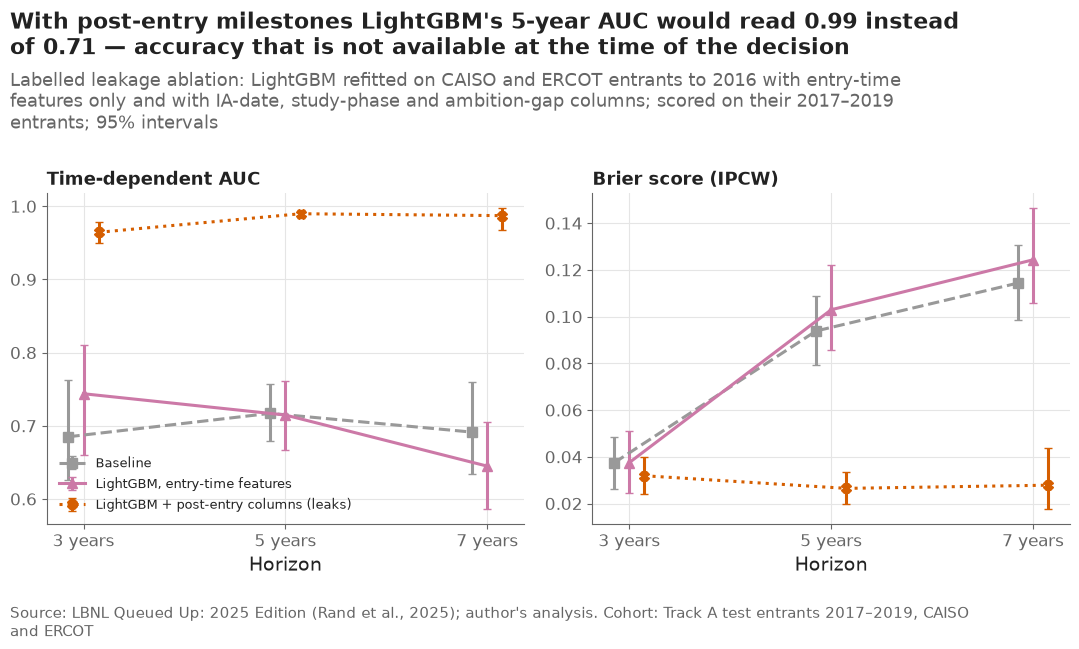

In [25]:
ABL_LABELS = {"baseline": "Baseline", "entry_only": "LightGBM, entry-time features",
              "with_post_entry": "LightGBM + post-entry columns (leaks)"}
ABL_STYLE = {"baseline": dict(color="#999999", marker="s", linestyle="--"), "entry_only": dict(color="#CC79A7", marker="^"),
             "with_post_entry": dict(color="#D55E00", marker="X", linestyle=":")}
abl_offsets = dict(zip(ABL_LABELS, [-0.15, 0, 0.15]))
fig, axes = plt.subplots(1, 2, sharex=True)
for ax, metric in zip(axes, ["auc", "brier"]):
    for model in ABL_LABELS:
        part = ablation[(ablation["model"] == model) & (ablation["metric"] == metric)]
        errorbars(ax, part["horizon"] + abl_offsets[model], part, label=ABL_LABELS[model], **ABL_STYLE[model])
    ax.set_xticks(HORIZONS, [f"{h} years" for h in HORIZONS])
    ax.set_xlabel("Horizon")
    ax.set_title(METRIC_LABELS[metric], fontsize=13)
axes[0].legend(loc="lower left", fontsize=9.5)
plots.finish(fig,
             f"With post-entry milestones LightGBM's 5-year AUC would read {value(ablation, 'with_post_entry', 'auc', 5):.2f} "
             f"instead of {value(ablation, 'entry_only', 'auc', 5):.2f} — accuracy that is not available at the time of "
             "the decision",
             "Labelled leakage ablation: LightGBM refitted on CAISO and ERCOT entrants to 2016 with entry-time features "
             "only and with IA-date, study-phase and ambition-gap columns; scored on their 2017–2019 entrants; 95% intervals",
             "Track A test entrants 2017–2019, CAISO and ERCOT")
save(fig, "08_16_leakage_ablation", "Leakage ablation: time-dependent AUC and Brier score with and without post-entry columns, CAISO and ERCOT.")
plt.show()

**Reading this.** Adding the four post-entry columns makes LightGBM look nearly perfect on CAISO and ERCOT: 5-year AUC 0.990 [0.984, 0.995] instead of 0.715 [0.667, 0.761], Brier 0.026 instead of 0.103, and 58.9% of the trees' split gain goes to those columns. This is leakage, not skill: whether an interconnection agreement was recorded and the study phase as of 2024 are partly the outcome itself, and the stored ambition gap was found in notebook 01 to be updated after entry (decision #22). A model reported with these columns would promise accuracy that does not exist on the day a request enters the queue. A side result: fitted on CAISO and ERCOT alone, the entry-time LightGBM does not beat the baseline there (AUC 0.715 vs 0.717 at 5 years), consistent with the within-region results above.

## 10. Robustness reruns

The main choices are re-made one at a time, refitting the baseline and both
discrete-time models on entrants to 2016 with notebook 06's settings (Cox is
not refitted; it is not a primary model) and scoring the variant's test set:

- **main** — refitted as a check that the refit reproduces notebook 06;
- **ERCOT dates as recorded** — no delayed entry (decision #21's sensitivity run);
- **ERCOT stamped dates imputed** — each stamped withdrawal gets a time drawn
  from PJM and CAISO withdrawals of the same entry year that happened earlier
  (notebook 04's method, donors from entrants to 2016), no delayed entry;
- **suspended as withdrawn** — suspended requests count as withdrawn at their
  censoring date, in fitting and in scoring (decision #4's sensitivity run);
- **under 20 MW excluded** — requests below the FERC small-generator step
  dropped from fitting and scoring.

In [26]:
def impute_stamped(frame, seed=2026):
    """ERCOT's stamped withdrawals with times drawn from earlier PJM/CAISO withdrawals of the same entry year."""
    out = frame.copy()
    donors = frame[frame["region"].isin(["PJM", "CAISO"]) & (frame["event"] == 2)]
    rng = np.random.default_rng(seed)
    for i in out.index[out["wd_bulk_date"].fillna(False).astype(bool)]:
        cap = out.at[i, "duration_years"]
        pool = donors.loc[(donors["q_year"] == out.at[i, "q_year"]) & (donors["duration_years"] <= cap), "duration_years"]
        if pool.empty:
            pool = donors.loc[donors["duration_years"] <= cap, "duration_years"]
        out.at[i, "duration_years"] = rng.choice(pool.to_numpy())
    return out


def suspended_as_withdrawn(frame):
    """Suspended requests (censored in the main models) recoded as withdrawn at their censoring time."""
    out = frame.copy()
    out.loc[(out["q_status"] == "suspended") & (out["event"] == 0), "event"] = 2
    return out


def at_least_20(frame):
    """Requests in a size regime of 20 MW or more (size = first component, as in the features of notebook 04)."""
    return ~frame["size_regime"].astype(str).isin(["<5", "5–<20"])


VARIANTS = {
    "main": (final, test, True),
    "ERCOT dates as recorded": (final, test, False),
    "ERCOT stamped dates imputed": (impute_stamped(final), test, False),
    "suspended as withdrawn": (suspended_as_withdrawn(final), suspended_as_withdrawn(test), True),
    "under 20 MW excluded": (final[at_least_20(final)], test[at_least_20(test)], True),
}
rob_tables, rob_sizes, refit_gap = [], [], {}
for v_i, (name, (train_v, test_v, delayed)) in enumerate(VARIANTS.items()):
    fitted = discrete_time.fit_both(train_v, clean, tuning, delayed=delayed)
    p_v = discrete_time.predict_both(fitted, test_v)
    base_v = survival_tools.baseline_cif(train_v, test_v, HORIZONS)
    if name == "main":
        refit_gap = {m: max(float(np.abs(p_v[m][h].to_numpy() - preds[h][m]).max()) for h in HORIZONS) for m in ["dt_logit", "dt_lgbm"]}
        refit_gap["baseline"] = max(float(np.abs(base_v[h].to_numpy() - preds[h]["baseline"]).max()) for h in HORIZONS)
    d_v, e_v = test_v["duration_years"].to_numpy(), test_v["event"].to_numpy()
    fu_v = ((pd.Timestamp(config.CENSOR_DATE) - test_v["q_date"]).dt.days / config.DAYS_PER_YEAR).to_numpy()
    G_v = evaluation.censoring_km(fu_v, np.ones(len(test_v), dtype=bool))
    rob_sizes.append({"variant": name, "train_requests": len(train_v), "test_requests": len(test_v),
                      "train_project_years": len(fitted["rows"])})
    for h in HORIZONS:
        sub = {"baseline": base_v[h].to_numpy(), "dt_logit": p_v["dt_logit"][h].to_numpy(), "dt_lgbm": p_v["dt_lgbm"][h].to_numpy()}
        point = evaluation.score_horizon(sub, d_v, e_v, h, G_v)
        draws = evaluation.bootstrap(lambda sw: evaluation.score_horizon(sub, d_v, e_v, h, G_v, sw), len(test_v), N_BOOT,
                                     REGISTERED["seed_track_a"] + 50 + v_i)
        table = evaluation.summarise(point, draws, level=LEVEL)
        table.insert(0, "variant", name)
        table.insert(3, "horizon", h)
        rob_tables.append(table)
robustness = pd.concat(rob_tables, ignore_index=True)
robustness.to_csv(paths.RESULTS / "robustness.csv", index=False)
print("largest gap between the main refit and the stored predictions:", {k: f"{v:.1e}" for k, v in refit_gap.items()})
print(f"robustness done at {(time.time() - START) / 60:.1f} minutes")
pd.DataFrame(rob_sizes).set_index("variant")

largest gap between the main refit and the stored predictions: {'dt_logit': '0.0e+00', 'dt_lgbm': '0.0e+00', 'baseline': '0.0e+00'}
robustness done at 3.9 minutes


,train_requests,test_requests,train_project_years
variant,,,
main,5298,2268,14653
ERCOT dates as recorded,5298,2268,19331
ERCOT stamped dates imputed,5298,2268,16957
suspended as withdrawn,5298,2268,14669
under 20 MW excluded,3686,1839,10332


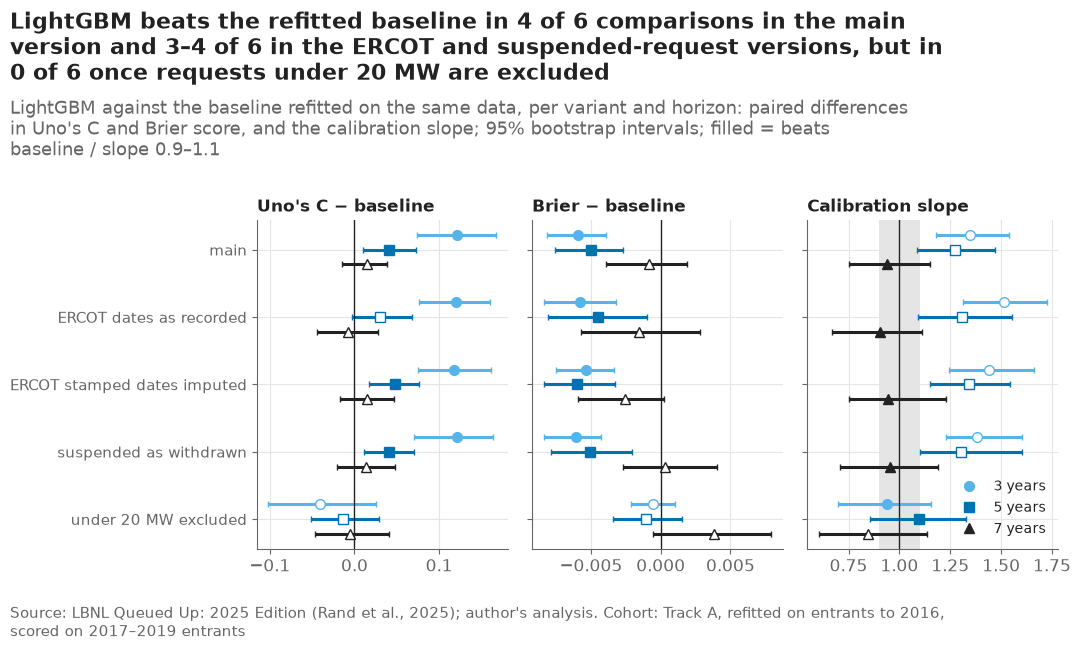

metric                                         brier                                                                slope                     \
horizon                                            3                        5                        7                  3                  5   
variant                                                                                                                                        
main                         -0.006 [-0.008, -0.004]  -0.005 [-0.008, -0.003]  -0.001 [-0.004, +0.002]  1.34 [1.18, 1.54]  1.27 [1.08, 1.47]   
ERCOT dates as recorded      -0.006 [-0.008, -0.003]  -0.004 [-0.008, -0.001]  -0.002 [-0.006, +0.003]  1.51 [1.31, 1.72]  1.31 [1.09, 1.56]   
ERCOT stamped dates imputed  -0.005 [-0.008, -0.003]  -0.006 [-0.008, -0.003]  -0.003 [-0.006, +0.000]  1.44 [1.24, 1.66]  1.34 [1.15, 1.54]   
suspended as withdrawn       -0.006 [-0.008, -0.004]  -0.005 [-0.008, -0.002]  +0.000 [-0.003, +0.004]  1.38 [1.23, 1.60]  1.31 [1.10, 1.60]   
under 20 MW excluded         -0.001 [-0.002, +0.001]  -0.001 [-0.003, +0.002]  +0.004 [-0.001, +0.008]  0.94 [0.70, 1.15]  1.10 [0.86, 1.33]   

metric                                                            uno_c                                                    
horizon                                      7                        3                        5                        7  
variant                                                                                                                    
main                         0.94 [0.75, 1.15]  +0.121 [+0.074, +0.168]  +0.041 [+0.010, +0.073]  +0.015 [-0.014, +0.038]  
ERCOT dates as recorded      0.91 [0.67, 1.11]  +0.120 [+0.076, +0.160]  +0.030 [-0.003, +0.068]  -0.008 [-0.044, +0.028]  
ERCOT stamped dates imputed  0.94 [0.75, 1.23]  +0.117 [+0.075, +0.162]  +0.048 [+0.017, +0.076]  +0.014 [-0.017, +0.047]  
suspended as withdrawn       0.95 [0.71, 1.19]  +0.121 [+0.070, +0.164]  +0.041 [+0.012, +0.070]  +0.014 [-0.020, +0.048]  
under 20 MW excluded         0.85 [0.60, 1.14]  -0.040 [-0.102, +0.025]  -0.014 [-0.051, +0.030]  -0.006 [-0.046, +0.040]

In [27]:
fig, axes = plt.subplots(1, 3, sharey=True, figsize=(11, 6.5))
names = list(VARIANTS)
for ax, metric in zip(axes, ["uno_c", "brier", "slope"]):
    for h_i, h in enumerate(HORIZONS):
        part = robustness[(robustness["model"] == "dt_lgbm") & (robustness["metric"] == metric)
                          & (robustness["horizon"] == h)].set_index("variant").loc[names]
        y = np.arange(len(names)) + (h_i - 1) * 0.22
        if metric == "slope":
            est, low, high = part["estimate"], part["low"], part["high"]
        else:
            est, low, high = part["diff"], part["diff_low"], part["diff_high"]
        filled = part["beats"].astype(bool) if metric != "slope" else (est.between(0.9, 1.1))
        for yy, e_, l_, h_, f_ in zip(y, est, low, high, filled):
            ax.errorbar(e_, yy, xerr=[[e_ - l_], [h_ - e_]], fmt=["o", "s", "^"][h_i], color=["#56B4E9", "#0072B2", "#222222"][h_i],
                        markerfacecolor=["#56B4E9", "#0072B2", "#222222"][h_i] if f_ else "white", capsize=2, markersize=7)
    if metric == "slope":
        ax.axvspan(0.9, 1.1, color="#E5E5E5")
        ax.axvline(1, color=plots.INK, linewidth=1)
    else:
        ax.axvline(0, color=plots.INK, linewidth=1)
    ax.set_title({"uno_c": "Uno's C − baseline", "brier": "Brier − baseline",
                  "slope": "Calibration slope"}[metric], fontsize=12)
axes[0].set_yticks(range(len(names)), names, fontsize=11)
axes[0].invert_yaxis()
for h_i, h in enumerate(HORIZONS):
    axes[2].errorbar([], [], fmt=["o", "s", "^"][h_i], color=["#56B4E9", "#0072B2", "#222222"][h_i], label=f"{h} years")
axes[2].legend(loc="lower right", fontsize=10)
rb = robustness[(robustness["model"] == "dt_lgbm") & robustness["metric"].isin(["uno_c", "brier"])]
wins = rb.groupby("variant")["beats"].sum().astype(int)
others = wins.drop(["main", "under 20 MW excluded"])
plots.finish(fig,
             f"LightGBM beats the refitted baseline in {wins['main']} of 6 comparisons in the main version and "
             f"{others.min()}–{others.max()} of 6 in the ERCOT and suspended-request versions, but in "
             f"{wins['under 20 MW excluded']} of 6 once requests under 20 MW are excluded",
             "LightGBM against the baseline refitted on the same data, per variant and horizon: paired differences in Uno's "
             "C and Brier score, and the calibration slope; 95% bootstrap intervals; filled = beats baseline / slope 0.9–1.1",
             "Track A, refitted on entrants to 2016, scored on 2017–2019 entrants")
save(fig, "08_17_robustness", "Robustness reruns: LightGBM versus the baseline under five data versions, three horizons.")
plt.show()
rv = robustness[(robustness["model"] == "dt_lgbm") & robustness["metric"].isin(["uno_c", "brier"])].copy()
rv["difference"] = [f"{r.diff:+.3f} [{r.diff_low:+.3f}, {r.diff_high:+.3f}]" for r in rv.itertuples()]
rs = robustness[(robustness["model"] == "dt_lgbm") & (robustness["metric"] == "slope")].copy()
rs["difference"] = [f"{r.estimate:.2f} [{r.low:.2f}, {r.high:.2f}]" for r in rs.itertuples()]
pd.concat([rv, rs]).pivot_table(index="variant", columns=["metric", "horizon"], values="difference", aggfunc="first").loc[names]

**Reading this.** Refitting the main version reproduces notebooks 05–06 exactly (largest gap 0.0). LightGBM beats the refitted baseline in 4 of 6 Uno/Brier comparisons (3 and 5 years) in the main version, in 3 of 6 when ERCOT's stamped dates are kept as recorded, and in 4 of 6 when they are imputed or when suspended requests count as withdrawn; the 7-year comparisons stay inconclusive throughout, and the calibration slopes at 3 and 5 years stay above 1.1 (1.31–1.51). The one choice that changes the conclusion is excluding requests under 20 MW (3,686 training and 1,839 test requests remain): LightGBM then beats the baseline in none of the 6 comparisons (Uno's C at 3 years −0.040 [−0.102, +0.025]), although its calibration slopes move into or near the target (0.94, 1.10, 0.85). Much of the model's advantage therefore comes from recognising small requests, which reach operation fast under the small-generator procedures, and among requests of 20 MW and more it ranks no better than region × technology. That is an important limit for developers of utility-scale projects, and it is stated in the report.

## 11. Checks

In [28]:
decisions_text = (paths.DOCS / "decisions.md").read_text(encoding="utf-8")
runtime = time.time() - START
checks = pd.DataFrame([
    ("decision #5 holds the pre-registered criteria", "*Primary models, named before scoring:*" in decisions_text),
    ("every model × horizon × metric has a 95% interval", bool(all_metrics[["low", "high"]].notna().all().all())),
    ("success_criteria.csv: one PASS/FAIL line per registered criterion × horizon",
     len(criteria) == sum(len(c["horizons"]) for c in REGISTERED["criteria"]) and criteria["result"].isin(["PASS", "FAIL"]).all()),
    ("censoring is administrative: censored durations equal the follow-up windows",
     bool(np.allclose(durations[events == 0], follow_up[events == 0]))),
    ("weights are 1 for every test request at 3 and 5 years", bool((weights[3] == 1).all() and (weights[5] == 1).all())),
    ("refitting the main version reproduces notebooks 05–06 (largest gap < 1e-9)", max(refit_gap.values()) < 1e-9),
    ("tests/test_evaluation.py exists (metrics checked by hand)", (paths.REPO / "tests" / "test_evaluation.py").exists()),
], columns=["check", "passed"])
checks["result"] = np.where(checks["passed"], "PASS", "FAIL")
checks.to_csv(paths.RESULTS / "evaluate_checks.csv", index=False)
print(f"run time: {runtime / 60:.1f} minutes")
checks[["check", "result"]]

run time: 3.9 minutes


,check,result
0,decision #5 holds the pre-registered criteria,PASS
1,every model × horizon × metric has a 95% interval,PASS
2,success_criteria.csv: one PASS/FAIL line per r...,PASS
3,censoring is administrative: censored duration...,PASS
4,weights are 1 for every test request at 3 and ...,PASS
5,refitting the main version reproduces notebook...,PASS
6,tests/test_evaluation.py exists (metrics check...,PASS


**Reading this.** All seven checks pass: decision #5 holds the criteria, every model × horizon × metric has a 95% interval, success_criteria.csv has one PASS/FAIL line per registered line, censoring is administrative, the weights are 1 at 3 and 5 years, the main refit reproduces the stored predictions, and the metrics are tested by hand in tests/test_evaluation.py. Run time is under five minutes (printed above; it varies between runs).

## Takeaways

- 8 of 12 pre-registered criterion lines pass. The discrete-time LightGBM beats the region × technology baseline on concordance and Brier score at 3 and 5 years (Uno's C +0.121 and +0.041, intervals above zero) but not at 7 years, where its gain is inside the noise.
- Its ranking is useful: its top decile reached operation within 5 years 39.7% of the time (lift 3.96, criterion C4 passes). Its probabilities are too high in the middle of the range (calibration slope 1.34 and 1.27 at 3 and 5 years, C3 fails), mostly in PJM and for 2018–2019 entrants, whose completion fell below anything the training years showed.
- Cox, not a primary model, beats the baseline at every horizon and is the best model at 7 years; the region-specific timing model does not transfer to an unseen region.
- Track B's calibrated LightGBM beats the base rate on the 2017 cohort (AUC 0.608 vs 0.525), but stays a weak, coarse ranking.
- The advantage over the baseline disappears when requests under 20 MW are excluded, and post-entry milestones would inflate AUC to 0.99 — both are limits the report states plainly.

**What goes to the report:** F5 and F4 (results section), 08_12 (criteria table as a figure, with results/success_criteria.csv), 08_14 (drift after 2017), 08_17 (robustness, the 20 MW finding), 08_16 (leakage), 08_15 (leave-one-ISO-out, limitations), 08_10 (Track B); numbers from results/metrics.csv and results/success_criteria.csv.